In [1]:
pip install pandas duckdb

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
from pathlib import Path

ROOT = Path(r"D:\DS Project\Major")

files = sorted(ROOT.rglob("transactions_*.csv"))

total_rows = 0

print("Starting transaction profiling...\n")

for i, file in enumerate(files, 1):
    rows = sum(
        len(chunk)
        for chunk in pd.read_csv(
            file,
            usecols=["SHOP_DATE"],
            chunksize=500_000
        )
    )

    total_rows += rows
    print(f"{i}/{len(files)} | {file.name} | {rows:,} rows")

print("\n========== FINAL RESULT ==========")
print("Transaction files:", len(files))
print("Total transaction rows:", f"{total_rows:,}")


Starting transaction profiling...

1/117 | transactions_200607.csv | 2,481,430 rows
2/117 | transactions_200608.csv | 2,543,145 rows
3/117 | transactions_200609.csv | 2,633,216 rows
4/117 | transactions_200610.csv | 2,609,027 rows
5/117 | transactions_200611.csv | 2,538,463 rows
6/117 | transactions_200612.csv | 2,596,628 rows
7/117 | transactions_200613.csv | 2,615,378 rows
8/117 | transactions_200614.csv | 2,624,121 rows
9/117 | transactions_200615.csv | 2,687,882 rows
10/117 | transactions_200616.csv | 2,626,602 rows
11/117 | transactions_200617.csv | 2,598,869 rows
12/117 | transactions_200618.csv | 2,690,395 rows
13/117 | transactions_200619.csv | 2,605,667 rows
14/117 | transactions_200620.csv | 2,614,419 rows
15/117 | transactions_200621.csv | 2,695,053 rows
16/117 | transactions_200622.csv | 2,651,106 rows
17/117 | transactions_200623.csv | 2,572,576 rows
18/117 | transactions_200624.csv | 2,551,979 rows
19/117 | transactions_200625.csv | 2,593,292 rows
20/117 | transactions_20

In [3]:
import duckdb
import pandas as pd
from pathlib import Path

ROOT = Path(r"D:\DS Project\Major\Dataset")

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
files = sorted(ROOT.rglob("transactions_*.csv"))

print("Total transaction files:", len(files))

for file in files[:5]:
    print(file.name)

Total transaction files: 117
transactions_200607.csv
transactions_200608.csv
transactions_200609.csv
transactions_200610.csv
transactions_200611.csv


In [5]:

import duckdb
import pandas as pd
from pathlib import Path

ROOT = Path(r"D:\DS Project\Major")

TEMP = ROOT / "duckdb_temp"
TEMP.mkdir(exist_ok=True)

con = duckdb.connect()

con.execute("SET memory_limit = '1GB'")
con.execute("SET threads = 1")
con.execute("SET preserve_insertion_order = false")
con.execute(f"SET temp_directory = '{TEMP.as_posix()}'")

print("DuckDB ready!")

DuckDB ready!


In [6]:

files = sorted(ROOT.rglob("transactions_*.csv"))

results = []

print(f"Processing {len(files)} files...\n")

for i, file in enumerate(files, 1):

    query = """
    SELECT
        COUNT(*) AS total_rows,
        SUM(SPEND) AS total_revenue,
        SUM(QUANTITY) AS total_units
    FROM read_csv_auto(?)
    """

    row = con.execute(query, [str(file)]).fetchone()

    results.append({
        "file": file.name,
        "rows": row[0],
        "revenue": row[1],
        "units": row[2]
    })

    print(
        f"{i}/117 | {file.name} | "
        f"{row[0]:,} rows"
    )

profile_df = pd.DataFrame(results)

profile_df.to_csv(
    ROOT / "transaction_profile.csv",
    index=False
)

print("\n========== FINAL PROFILE ==========")
print("Total rows:", f"{profile_df['rows'].sum():,}")
print("Total revenue:", round(profile_df['revenue'].sum(), 2))
print("Total units:", f"{profile_df['units'].sum():,}")

display(profile_df.head())


Processing 117 files...

1/117 | transactions_200607.csv | 2,481,430 rows
2/117 | transactions_200608.csv | 2,543,145 rows
3/117 | transactions_200609.csv | 2,633,216 rows
4/117 | transactions_200610.csv | 2,609,027 rows
5/117 | transactions_200611.csv | 2,538,463 rows
6/117 | transactions_200612.csv | 2,596,628 rows
7/117 | transactions_200613.csv | 2,615,378 rows
8/117 | transactions_200614.csv | 2,624,121 rows
9/117 | transactions_200615.csv | 2,687,882 rows
10/117 | transactions_200616.csv | 2,626,602 rows
11/117 | transactions_200617.csv | 2,598,869 rows
12/117 | transactions_200618.csv | 2,690,395 rows
13/117 | transactions_200619.csv | 2,605,667 rows
14/117 | transactions_200620.csv | 2,614,419 rows
15/117 | transactions_200621.csv | 2,695,053 rows
16/117 | transactions_200622.csv | 2,651,106 rows
17/117 | transactions_200623.csv | 2,572,576 rows
18/117 | transactions_200624.csv | 2,551,979 rows
19/117 | transactions_200625.csv | 2,593,292 rows
20/117 | transactions_200626.csv |

,file,rows,revenue,units
0,transactions_200607.csv,2481430,4.760023e+06,3625242
1,transactions_200608.csv,2543145,4.733702e+06,3648899
2,transactions_200609.csv,2633216,5.066870e+06,3837942
3,transactions_200610.csv,2609027,5.029662e+06,3802058
4,transactions_200611.csv,2538463,4.827112e+06,3684901


In [7]:

files = sorted(ROOT.rglob("transactions_*.csv"))

quality_results = []

for i, file in enumerate(files, 1):

    query = """
    SELECT
        COUNT(*) AS total_rows,

        COUNT(*) FILTER (
            WHERE SHOP_DATE IS NULL
        ) AS missing_dates,

        COUNT(*) FILTER (
            WHERE CUST_CODE IS NULL
        ) AS missing_customers,

        COUNT(*) FILTER (
            WHERE PROD_CODE IS NULL
        ) AS missing_products,

        COUNT(*) FILTER (
            WHERE SPEND < 0
        ) AS negative_spend,

        COUNT(*) FILTER (
            WHERE QUANTITY < 0
        ) AS negative_quantity

    FROM read_csv_auto(?)
    """

    result = con.execute(
        query, [str(file)]
    ).fetchone()

    quality_results.append(result)

    print(f"{i}/{len(files)} completed")

columns = [
    "total_rows",
    "missing_dates",
    "missing_customers",
    "missing_products",
    "negative_spend",
    "negative_quantity"
]

quality_df = pd.DataFrame(
    quality_results,
    columns=columns
)

display(quality_df.sum().to_frame("Total"))


1/117 completed
2/117 completed
3/117 completed
4/117 completed
5/117 completed
6/117 completed
7/117 completed
8/117 completed
9/117 completed
10/117 completed
11/117 completed
12/117 completed
13/117 completed
14/117 completed
15/117 completed
16/117 completed
17/117 completed
18/117 completed
19/117 completed
20/117 completed
21/117 completed
22/117 completed
23/117 completed
24/117 completed
25/117 completed
26/117 completed
27/117 completed
28/117 completed
29/117 completed
30/117 completed
31/117 completed
32/117 completed
33/117 completed
34/117 completed
35/117 completed
36/117 completed
37/117 completed
38/117 completed
39/117 completed
40/117 completed
41/117 completed
42/117 completed
43/117 completed
44/117 completed
45/117 completed
46/117 completed
47/117 completed
48/117 completed
49/117 completed
50/117 completed
51/117 completed
52/117 completed
53/117 completed
54/117 completed
55/117 completed
56/117 completed
57/117 completed
58/117 completed
59/117 completed
60/117

,Total
total_rows,307532073
missing_dates,0
missing_customers,59534209
missing_products,0
negative_spend,0
negative_quantity,0


In [8]:

from pathlib import Path
import duckdb
import pandas as pd

ROOT = Path(r"D:\DS Project\Major")

# First transaction CSV
sample_file = sorted(
    ROOT.rglob("transactions_*.csv")
)[0]

print("Selected file:", sample_file.name)

query = """
SELECT
    COUNT(*) AS total_rows,

    COUNT(*) FILTER (
        WHERE CUST_CODE IS NULL
    ) AS missing_customers,

    COUNT(DISTINCT BASKET_ID) FILTER (
        WHERE CUST_CODE IS NULL
    ) AS anonymous_baskets,

    COUNT(*) FILTER (
        WHERE CUST_CODE IS NULL
        AND BASKET_ID IS NULL
    ) AS missing_customer_and_basket,

    ROUND(
        SUM(SPEND) FILTER (
            WHERE CUST_CODE IS NULL
        ), 2
    ) AS anonymous_revenue

FROM read_csv_auto(?)
"""

result = con.execute(
    query, [str(sample_file)]
).df()

display(result)


Selected file: transactions_200607.csv


,total_rows,missing_customers,anonymous_baskets,missing_customer_and_basket,anonymous_revenue
0,2481430,481137,76291,0,930385.09


In [9]:

files = sorted(ROOT.rglob("transactions_*.csv"))

all_results = []

for i, file in enumerate(files, 1):

    query = """
    SELECT
        COUNT(*) AS total_rows,

        COUNT(*) FILTER (
            WHERE CUST_CODE IS NULL
        ) AS missing_customers,

        COUNT(DISTINCT BASKET_ID) FILTER (
            WHERE CUST_CODE IS NULL
        ) AS anonymous_baskets,

        COUNT(*) FILTER (
            WHERE CUST_CODE IS NULL
            AND BASKET_ID IS NULL
        ) AS missing_both,

        SUM(SPEND) FILTER (
            WHERE CUST_CODE IS NULL
        ) AS anonymous_revenue

    FROM read_csv_auto(?)
    """

    row = con.execute(
        query, [str(file)]
    ).fetchone()

    all_results.append({
        "file": file.name,
        "total_rows": row[0],
        "missing_customers": row[1],
        "anonymous_baskets": row[2],
        "missing_both": row[3],
        "anonymous_revenue": row[4]
    })

    print(f"{i}/117 completed")

anonymous_df = pd.DataFrame(all_results)

display(anonymous_df.sum(numeric_only=True))

anonymous_df.to_csv(
    ROOT / "anonymous_customer_analysis.csv",
    index=False
)


1/117 completed
2/117 completed
3/117 completed
4/117 completed
5/117 completed
6/117 completed
7/117 completed
8/117 completed
9/117 completed
10/117 completed
11/117 completed
12/117 completed
13/117 completed
14/117 completed
15/117 completed
16/117 completed
17/117 completed
18/117 completed
19/117 completed
20/117 completed
21/117 completed
22/117 completed
23/117 completed
24/117 completed
25/117 completed
26/117 completed
27/117 completed
28/117 completed
29/117 completed
30/117 completed
31/117 completed
32/117 completed
33/117 completed
34/117 completed
35/117 completed
36/117 completed
37/117 completed
38/117 completed
39/117 completed
40/117 completed
41/117 completed
42/117 completed
43/117 completed
44/117 completed
45/117 completed
46/117 completed
47/117 completed
48/117 completed
49/117 completed
50/117 completed
51/117 completed
52/117 completed
53/117 completed
54/117 completed
55/117 completed
56/117 completed
57/117 completed
58/117 completed
59/117 completed
60/117

total_rows           3.075321e+08
missing_customers    5.953421e+07
anonymous_baskets    9.661352e+06
missing_both         0.000000e+00
anonymous_revenue    1.154495e+08
dtype: float64

In [10]:

files = sorted(ROOT.rglob("transactions_*.csv"))

all_results = []

for i, file in enumerate(files, 1):

    query = """
    SELECT
        COUNT(*) AS total_rows,

        COUNT(*) FILTER (
            WHERE CUST_CODE IS NULL
        ) AS missing_customers,

        COUNT(DISTINCT BASKET_ID) FILTER (
            WHERE CUST_CODE IS NULL
        ) AS anonymous_baskets,

        COUNT(*) FILTER (
            WHERE CUST_CODE IS NULL
            AND BASKET_ID IS NULL
        ) AS missing_both,

        SUM(SPEND) FILTER (
            WHERE CUST_CODE IS NULL
        ) AS anonymous_revenue

    FROM read_csv_auto(?)
    """

    row = con.execute(
        query, [str(file)]
    ).fetchone()

    all_results.append({
        "file": file.name,
        "total_rows": row[0],
        "missing_customers": row[1],
        "anonymous_baskets": row[2],
        "missing_both": row[3],
        "anonymous_revenue": row[4]
    })

    print(f"{i}/117 completed")

anonymous_df = pd.DataFrame(all_results)

display(anonymous_df.sum(numeric_only=True))

anonymous_df.to_csv(
    ROOT / "anonymous_customer_analysis.csv",
    index=False
)

1/117 completed
2/117 completed
3/117 completed
4/117 completed
5/117 completed
6/117 completed
7/117 completed
8/117 completed
9/117 completed
10/117 completed
11/117 completed
12/117 completed
13/117 completed
14/117 completed
15/117 completed
16/117 completed
17/117 completed
18/117 completed
19/117 completed
20/117 completed
21/117 completed
22/117 completed
23/117 completed
24/117 completed
25/117 completed
26/117 completed
27/117 completed
28/117 completed
29/117 completed
30/117 completed
31/117 completed
32/117 completed
33/117 completed
34/117 completed
35/117 completed
36/117 completed
37/117 completed
38/117 completed
39/117 completed
40/117 completed
41/117 completed
42/117 completed
43/117 completed
44/117 completed
45/117 completed
46/117 completed
47/117 completed
48/117 completed
49/117 completed
50/117 completed
51/117 completed
52/117 completed
53/117 completed
54/117 completed
55/117 completed
56/117 completed
57/117 completed
58/117 completed
59/117 completed
60/117

total_rows           3.075321e+08
missing_customers    5.953421e+07
anonymous_baskets    9.661352e+06
missing_both         0.000000e+00
anonymous_revenue    1.154495e+08
dtype: float64

In [11]:

total_rows = int(anonymous_df["total_rows"].sum())

missing_rows = int(
    anonymous_df["missing_customers"].sum()
)

anonymous_revenue = anonymous_df[
    "anonymous_revenue"
].sum()

total_revenue = 589727167.5

print("===== ANONYMOUS TRANSACTION ANALYSIS =====")

print(
    "Missing Customer ID %:",
    round(missing_rows / total_rows * 100, 2)
)

print(
    "Anonymous Revenue %:",
    round(anonymous_revenue / total_revenue * 100, 2)
)

print(
    "Identified Revenue:",
    round(total_revenue - anonymous_revenue, 2)
)

print(
    "Identified Revenue %:",
    round(
        (total_revenue - anonymous_revenue)
        / total_revenue * 100, 2
    )
)


===== ANONYMOUS TRANSACTION ANALYSIS =====
Missing Customer ID %: 19.36
Anonymous Revenue %: 19.58
Identified Revenue: 474277678.8
Identified Revenue %: 80.42


In [12]:

import duckdb

con = duckdb.connect()

sample_file = files[0]

column_profile = con.execute("""
    DESCRIBE
    SELECT *
    FROM read_csv_auto(?)
""", [str(sample_file)]).df()

display(column_profile)


,column_name,column_type,null,key,default,extra
0,SHOP_WEEK,BIGINT,YES,None,None,None
1,SHOP_DATE,BIGINT,YES,None,None,None
2,SHOP_WEEKDAY,BIGINT,YES,None,None,None
3,SHOP_HOUR,BIGINT,YES,None,None,None
4,QUANTITY,BIGINT,YES,None,None,None
5,SPEND,DOUBLE,YES,None,None,None
6,PROD_CODE,VARCHAR,YES,None,None,None
7,PROD_CODE_10,VARCHAR,YES,None,None,None
8,PROD_CODE_20,VARCHAR,YES,None,None,None
9,PROD_CODE_30,VARCHAR,YES,None,None,None


In [13]:

import pandas as pd

files = sorted(ROOT.rglob("transactions_*.csv"))

missing_results = []

for i, file in enumerate(files, 1):

    query = """
    SELECT *
    FROM read_csv_auto(?)
    LIMIT 0
    """

    columns = con.execute(
        query, [str(file)]
    ).df().columns.tolist()

    query = """
    SELECT
        COUNT(*) AS total_rows,
        COUNT(*) - COUNT(CUST_CODE) AS missing_customer,
        COUNT(*) - COUNT(PROD_CODE) AS missing_product,
        COUNT(*) - COUNT(SPEND) AS missing_spend,
        COUNT(*) - COUNT(QUANTITY) AS missing_quantity,
        COUNT(*) - COUNT(BASKET_ID) AS missing_basket,
        COUNT(*) - COUNT(STORE_CODE) AS missing_store
    FROM read_csv_auto(?)
    """

    result = con.execute(
        query, [str(file)]
    ).fetchone()

    missing_results.append({
        "file": file.name,
        "total_rows": result[0],
        "missing_customer": result[1],
        "missing_product": result[2],
        "missing_spend": result[3],
        "missing_quantity": result[4],
        "missing_basket": result[5],
        "missing_store": result[6]
    })

    print(f"{i}/117 completed")

missing_df = pd.DataFrame(missing_results)

summary = missing_df.select_dtypes(
    include="number"
).sum()

display(summary)


1/117 completed
2/117 completed
3/117 completed
4/117 completed
5/117 completed
6/117 completed
7/117 completed
8/117 completed
9/117 completed
10/117 completed
11/117 completed
12/117 completed
13/117 completed
14/117 completed
15/117 completed
16/117 completed
17/117 completed
18/117 completed
19/117 completed
20/117 completed
21/117 completed
22/117 completed
23/117 completed
24/117 completed
25/117 completed
26/117 completed
27/117 completed
28/117 completed
29/117 completed
30/117 completed
31/117 completed
32/117 completed
33/117 completed
34/117 completed
35/117 completed
36/117 completed
37/117 completed
38/117 completed
39/117 completed
40/117 completed
41/117 completed
42/117 completed
43/117 completed
44/117 completed
45/117 completed
46/117 completed
47/117 completed
48/117 completed
49/117 completed
50/117 completed
51/117 completed
52/117 completed
53/117 completed
54/117 completed
55/117 completed
56/117 completed
57/117 completed
58/117 completed
59/117 completed
60/117

total_rows          307532073
missing_customer     59534209
missing_product             0
missing_spend               0
missing_quantity            0
missing_basket              0
missing_store               0
dtype: int64

In [14]:

# Complete missing-value audit across all 22 columns

sample_file = files[0]

columns = con.execute(
    "DESCRIBE SELECT * FROM read_csv_auto(?)",
    [str(sample_file)]
).df()["column_name"].tolist()

missing_summary = []

for i, file in enumerate(files, 1):

    expressions = [
        f'COUNT(*) - COUNT("{col}") AS "{col}"'
        for col in columns
    ]

    query = f"""
        SELECT
            COUNT(*) AS total_rows,
            {", ".join(expressions)}
        FROM read_csv_auto(?)
    """

    result = con.execute(
        query, [str(file)]
    ).fetchone()

    missing_summary.append(result)

    print(f"{i}/117 completed")

# Aggregate all files
missing_df = pd.DataFrame(
    missing_summary,
    columns=["total_rows"] + columns
)

total_missing = missing_df.drop(
    columns=["total_rows"]
).sum()

total_rows = missing_df["total_rows"].sum()

audit = pd.DataFrame({
    "Column": total_missing.index,
    "Missing_Count": total_missing.values
})

audit["Missing_Percentage"] = (
    audit["Missing_Count"] / total_rows * 100
).round(3)

audit = audit.sort_values(
    "Missing_Percentage",
    ascending=False
)

display(audit)

audit.to_csv(
    ROOT / "complete_missing_value_audit.csv",
    index=False
)


1/117 completed
2/117 completed
3/117 completed
4/117 completed
5/117 completed
6/117 completed
7/117 completed
8/117 completed
9/117 completed
10/117 completed
11/117 completed
12/117 completed
13/117 completed
14/117 completed
15/117 completed
16/117 completed
17/117 completed
18/117 completed
19/117 completed
20/117 completed
21/117 completed
22/117 completed
23/117 completed
24/117 completed
25/117 completed
26/117 completed
27/117 completed
28/117 completed
29/117 completed
30/117 completed
31/117 completed
32/117 completed
33/117 completed
34/117 completed
35/117 completed
36/117 completed
37/117 completed
38/117 completed
39/117 completed
40/117 completed
41/117 completed
42/117 completed
43/117 completed
44/117 completed
45/117 completed
46/117 completed
47/117 completed
48/117 completed
49/117 completed
50/117 completed
51/117 completed
52/117 completed
53/117 completed
54/117 completed
55/117 completed
56/117 completed
57/117 completed
58/117 completed
59/117 completed
60/117

,Column,Missing_Count,Missing_Percentage
13,seg_2,89311523,29.041
11,CUST_CODE,59534209,19.359
12,seg_1,59534209,19.359
2,SHOP_WEEKDAY,0,0.000
0,SHOP_WEEK,0,0.000
1,SHOP_DATE,0,0.000
5,SPEND,0,0.000
4,QUANTITY,0,0.000
3,SHOP_HOUR,0,0.000
6,PROD_CODE,0,0.000


In [15]:

query = """
SELECT
    COUNT(*) AS total_rows,

    COUNT(*) FILTER (
        WHERE CUST_CODE IS NULL
    ) AS missing_customer,

    COUNT(*) FILTER (
        WHERE seg_1 IS NULL
    ) AS missing_seg1,

    COUNT(*) FILTER (
        WHERE seg_2 IS NULL
    ) AS missing_seg2,

    COUNT(*) FILTER (
        WHERE CUST_CODE IS NULL
        AND seg_2 IS NULL
    ) AS both_missing,

    COUNT(*) FILTER (
        WHERE CUST_CODE IS NOT NULL
        AND seg_2 IS NULL
    ) AS customer_present_seg2_missing,

    COUNT(*) FILTER (
        WHERE CUST_CODE IS NULL
        AND seg_2 IS NOT NULL
    ) AS customer_missing_seg2_present

FROM read_csv_auto(
    ?,
    union_by_name = true
)
"""

pattern = (
    ROOT / "**" / "transactions_*.csv"
).as_posix()

segment_analysis = con.execute(
    query, [pattern]
).df()

display(segment_analysis)


,total_rows,missing_customer,missing_seg1,missing_seg2,both_missing,customer_present_seg2_missing,customer_missing_seg2_present
0,307532073,59534209,59534209,89311523,59534209,29777314,0


In [16]:

pattern = (
    ROOT / "**" / "transactions_*.csv"
).as_posix()

query = f"""
SELECT
    COUNT(*) AS total_rows,

    COUNT(DISTINCT BASKET_ID)
        AS unique_baskets,

    COUNT(DISTINCT CUST_CODE)
        AS unique_customers,

    COUNT(DISTINCT PROD_CODE)
        AS unique_products,

    COUNT(*) - COUNT(DISTINCT BASKET_ID)
        AS rows_minus_unique_baskets

FROM read_csv_auto(
    '{pattern}',
    union_by_name = true
)
"""

duplicate_profile = con.execute(query).df()

display(duplicate_profile)


,total_rows,unique_baskets,unique_customers,unique_products,rows_minus_unique_baskets
0,307532073,47098503,494880,4997,260433570


In [17]:

query = f"""
SELECT
    COUNT(*) AS total_rows,

    COUNT(*) - COUNT(DISTINCT
        HASH(
            SHOP_WEEK,
            SHOP_DATE,
            SHOP_WEEKDAY,
            SHOP_HOUR,
            QUANTITY,
            SPEND,
            PROD_CODE,
            PROD_CODE_10,
            PROD_CODE_20,
            PROD_CODE_30,
            PROD_CODE_40,
            CUST_CODE,
            seg_1,
            seg_2,
            BASKET_ID,
            BASKET_SIZE,
            BASKET_PRICE_SENSITIVITY,
            BASKET_TYPE,
            BASKET_DOMINANT_MISSION,
            STORE_CODE,
            STORE_FORMAT
        )
    ) AS potential_duplicate_rows

FROM read_csv_auto(
    '{pattern}',
    union_by_name = true
)
"""

duplicate_check = con.execute(query).df()

display(duplicate_check)


,total_rows,potential_duplicate_rows
0,307532073,105


In [18]:

query = f"""
SELECT
    MIN(SHOP_DATE) AS first_shop_date,
    MAX(SHOP_DATE) AS last_shop_date,
    COUNT(DISTINCT SHOP_DATE) AS unique_shop_dates,
    COUNT(DISTINCT SHOP_WEEK) AS unique_shop_weeks,
    MIN(SHOP_WEEK) AS first_shop_week,
    MAX(SHOP_WEEK) AS last_shop_week
FROM read_csv_auto(
    '{pattern}',
    union_by_name = true
)
"""

date_profile = con.execute(query).df()

display(date_profile)


,first_shop_date,last_shop_date,unique_shop_dates,unique_shop_weeks,first_shop_week,last_shop_week
0,20060410,20080706,819,117,200607,200819


In [19]:

monthly_query = f"""
SELECT
    STRFTIME(
        STRPTIME(CAST(SHOP_DATE AS VARCHAR), '%Y%m%d'),
        '%Y-%m'
    ) AS month,

    ROUND(SUM(SPEND), 2) AS total_revenue,

    SUM(QUANTITY) AS total_units,

    COUNT(*) AS transaction_rows,

    ROUND(AVG(SPEND), 2) AS avg_row_spend

FROM read_csv_auto(
    '{pattern}',
    union_by_name = true
)

GROUP BY month
ORDER BY month
"""

monthly_df = con.execute(monthly_query).df()

display(monthly_df)


,month,total_revenue,total_units,transaction_rows,avg_row_spend
0,2006-04,14560595.32,11112083.0,7657791,1.90
1,2006-05,21889065.99,16649274.0,11484182,1.91
2,2006-06,21883540.96,16454762.0,11337148,1.93
3,2006-07,22652162.16,17046186.0,11699689,1.94
4,2006-08,21500471.36,16760675.0,11475829,1.87
5,2006-09,21271044.97,16811950.0,11369269,1.87
6,2006-10,20809793.17,16616488.0,11388498,1.83
7,2006-11,21288552.33,16567312.0,11267435,1.89
8,2006-12,24680929.00,17425145.0,11519724,2.14
9,2007-01,20835965.04,16790074.0,11541170,1.81


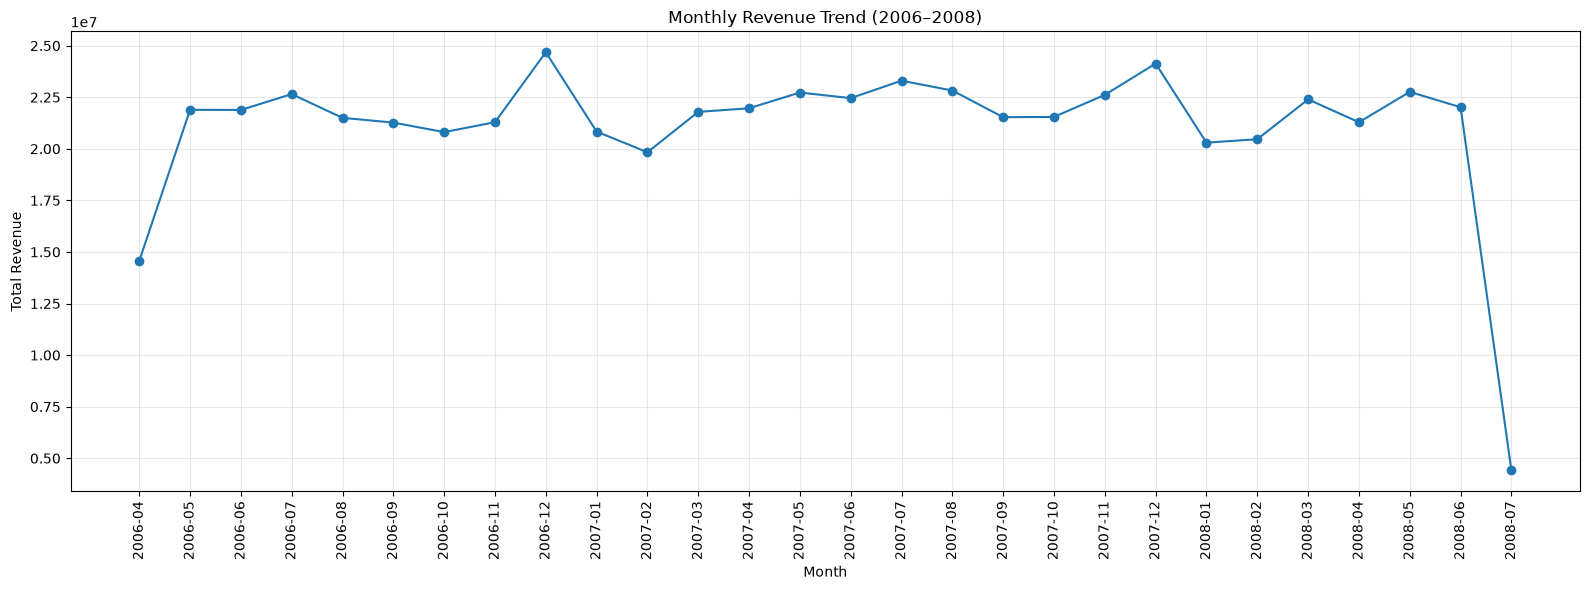

In [20]:

import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

plt.plot(
    monthly_df["month"],
    monthly_df["total_revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend (2006–2008)")
plt.xlabel("Month")
plt.ylabel("Total Revenue")

plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [21]:

monthly_query = f"""
SELECT
    STRFTIME(
        STRPTIME(CAST(SHOP_DATE AS VARCHAR), '%Y%m%d'),
        '%Y-%m'
    ) AS month,

    ROUND(SUM(SPEND), 2) AS total_revenue,

    SUM(QUANTITY) AS total_units,

    COUNT(*) AS transaction_rows,

    ROUND(AVG(SPEND), 2) AS avg_row_spend,

    COUNT(DISTINCT BASKET_ID) AS unique_baskets

FROM read_csv_auto(
    '{pattern}',
    union_by_name = true
)

GROUP BY month
ORDER BY month
"""

monthly_df = con.execute(monthly_query).df()

display(monthly_df)


,month,total_revenue,total_units,transaction_rows,avg_row_spend,unique_baskets
0,2006-04,14560595.32,11112083.0,7657791,1.90,1150425
1,2006-05,21889065.99,16649274.0,11484182,1.91,1733343
2,2006-06,21883540.96,16454762.0,11337148,1.93,1726834
3,2006-07,22652162.16,17046186.0,11699689,1.94,1792136
4,2006-08,21500471.36,16760675.0,11475829,1.87,1742166
5,2006-09,21271044.97,16811950.0,11369269,1.87,1715491
6,2006-10,20809793.17,16616488.0,11388498,1.83,1746723
7,2006-11,21288552.33,16567312.0,11267435,1.89,1720575
8,2006-12,24680929.00,17425145.0,11519724,2.14,1732348
9,2007-01,20835965.04,16790074.0,11541170,1.81,1692512


In [22]:

print("========== MONTHLY REVENUE INSIGHTS ==========")

print("\nHighest Revenue Month:")
display(
    monthly_df.loc[
        monthly_df["total_revenue"].idxmax()
    ]
)

print("\nLowest Revenue Month:")
display(
    monthly_df.loc[
        monthly_df["total_revenue"].idxmin()
    ]
)

print("\nAverage Monthly Revenue:")
print(round(monthly_df["total_revenue"].mean(), 2))

print("\nTotal Monthly Revenue:")
print(round(monthly_df["total_revenue"].sum(), 2))


========== MONTHLY REVENUE INSIGHTS ==========

Highest Revenue Month:


month                  2006-12
total_revenue       24680929.0
total_units         17425145.0
transaction_rows      11519724
avg_row_spend             2.14
unique_baskets         1732348
Name: 8, dtype: object


Lowest Revenue Month:


month                  2008-07
total_revenue       4406841.71
total_units          3459856.0
transaction_rows       2296593
avg_row_spend             1.92
unique_baskets          351831
Name: 27, dtype: object


Average Monthly Revenue:
21061684.55

Total Monthly Revenue:
589727167.5


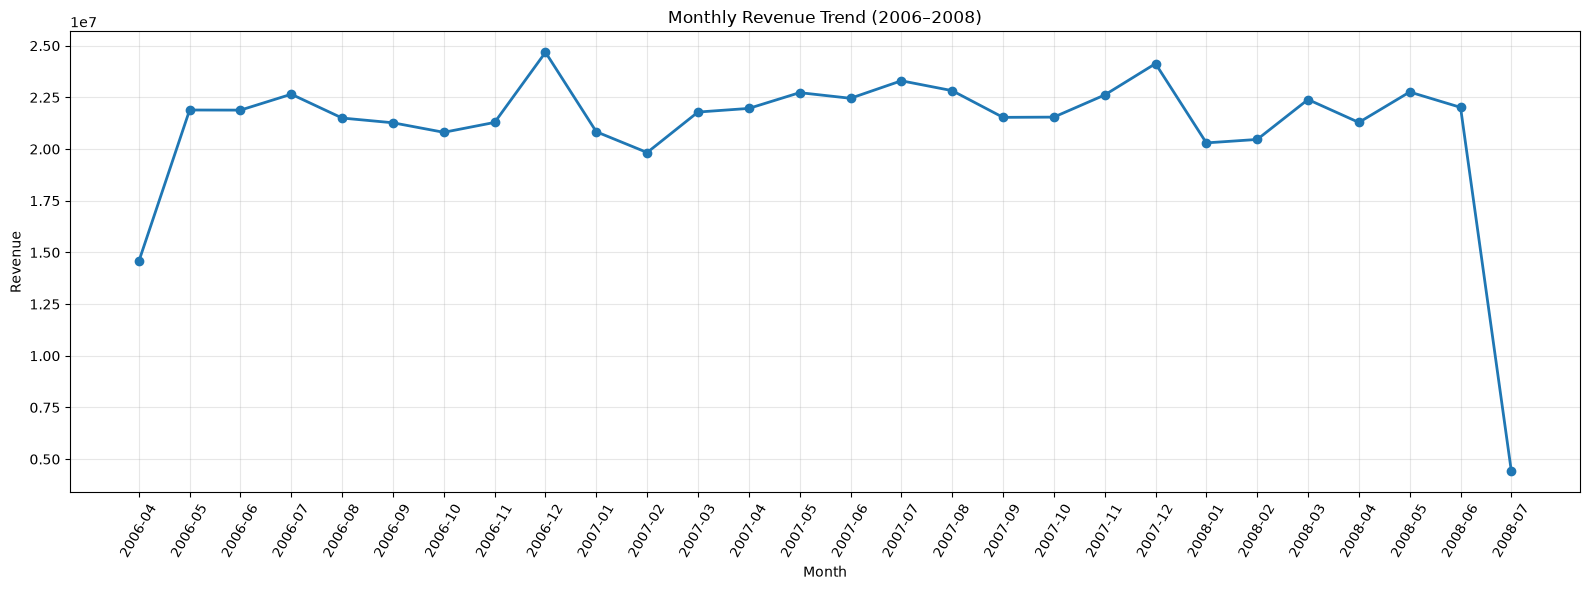

In [23]:

import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

plt.plot(
    monthly_df["month"],
    monthly_df["total_revenue"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend (2006–2008)")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=60)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [24]:

store_query = f"""
SELECT
    STORE_CODE,
    STORE_FORMAT,

    ROUND(SUM(SPEND), 2) AS total_revenue,

    SUM(QUANTITY) AS total_units,

    COUNT(*) AS transaction_rows,

    COUNT(DISTINCT BASKET_ID) AS unique_baskets,

    ROUND(AVG(SPEND), 2) AS avg_transaction_spend

FROM read_csv_auto(
    '{pattern}',
    union_by_name = true
)

GROUP BY STORE_CODE, STORE_FORMAT
ORDER BY total_revenue DESC
"""

store_df = con.execute(store_query).df()

print("Total Stores:", len(store_df))

display(store_df.head(20))


Total Stores: 761


,STORE_CODE,STORE_FORMAT,total_revenue,total_units,transaction_rows,unique_baskets,avg_transaction_spend
0,STORE00696,XLS,2405287.32,1760269.0,1162739,142575,2.07
1,STORE01758,XLS,2377295.80,1717702.0,1100963,132645,2.16
2,STORE00729,XLS,2262441.60,1645651.0,1077556,135359,2.10
3,STORE00343,XLS,2156792.76,1618556.0,1072314,139384,2.01
4,STORE01423,XLS,2136377.06,1621254.0,1063697,127010,2.01
5,STORE02206,XLS,2099111.01,1620282.0,1021266,118303,2.06
6,STORE02339,XLS,2086041.04,1564250.0,1028304,134005,2.03
7,STORE02504,XLS,2050161.96,1586189.0,1047283,115059,1.96
8,STORE01604,XLS,1988260.62,1572204.0,1010984,126912,1.97
9,STORE02561,XLS,1913164.77,1455127.0,930937,134843,2.06


In [25]:

print("========== STORE PERFORMANCE ==========")

print("Total Stores:", store_df["STORE_CODE"].nunique())

print(
    "Total Revenue:",
    round(store_df["total_revenue"].sum(), 2)
)

print(
    "Average Store Revenue:",
    round(store_df["total_revenue"].mean(), 2)
)

print("\nTOP 10 STORES BY REVENUE")

display(
    store_df.nlargest(10, "total_revenue")[
        ["STORE_CODE", "STORE_FORMAT", "total_revenue", "total_units"]
    ]
)

print("\nBOTTOM 10 STORES BY REVENUE")

display(
    store_df.nsmallest(10, "total_revenue")[
        ["STORE_CODE", "STORE_FORMAT", "total_revenue", "total_units"]
    ]
)


========== STORE PERFORMANCE ==========
Total Stores: 761
Total Revenue: 589727167.5
Average Store Revenue: 774937.15

TOP 10 STORES BY REVENUE


,STORE_CODE,STORE_FORMAT,total_revenue,total_units
0,STORE00696,XLS,2405287.32,1760269.0
1,STORE01758,XLS,2377295.80,1717702.0
2,STORE00729,XLS,2262441.60,1645651.0
3,STORE00343,XLS,2156792.76,1618556.0
4,STORE01423,XLS,2136377.06,1621254.0
5,STORE02206,XLS,2099111.01,1620282.0
6,STORE02339,XLS,2086041.04,1564250.0
7,STORE02504,XLS,2050161.96,1586189.0
8,STORE01604,XLS,1988260.62,1572204.0
9,STORE02561,XLS,1913164.77,1455127.0



BOTTOM 10 STORES BY REVENUE


,STORE_CODE,STORE_FORMAT,total_revenue,total_units
760,STORE00538,SS,56318.48,51601.0
759,STORE02012,SS,57201.03,53582.0
758,STORE00895,SS,60815.19,55226.0
757,STORE00091,SS,61434.57,56012.0
756,STORE01487,SS,62955.53,63922.0
755,STORE00691,SS,64181.70,59809.0
754,STORE01485,SS,66030.00,63341.0
753,STORE00779,SS,66062.53,66673.0
752,STORE01902,SS,67494.27,63505.0
751,STORE02779,SS,69022.93,66197.0


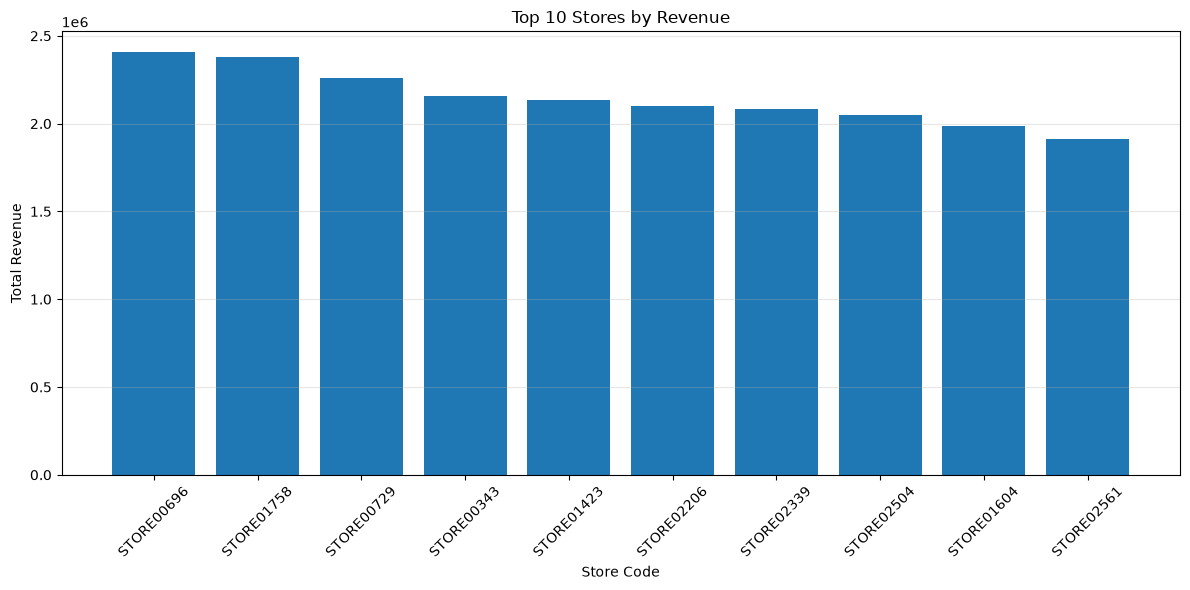

In [26]:

top_stores = store_df.nlargest(10, "total_revenue")

plt.figure(figsize=(12, 6))

plt.bar(
    top_stores["STORE_CODE"].astype(str),
    top_stores["total_revenue"]
)

plt.title("Top 10 Stores by Revenue")
plt.xlabel("Store Code")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [28]:
from pathlib import Path

ROOT = Path(r"D:\DS Project\Major")
files = sorted(ROOT.rglob("transactions_*.csv"))

print("Total files:", len(files))
print("First file:", files[0])

Total files: 117
First file: D:\DS Project\Major\Dataset\1\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-1-of-9)\transactions_200607.csv


In [4]:
parts = []

for i, file in enumerate(files, start=1):

    query = """
    SELECT
        PROD_CODE,
        PROD_CODE_10,
        PROD_CODE_20,
        PROD_CODE_30,
        PROD_CODE_40,
        SUM(SPEND) AS total_revenue,
        SUM(QUANTITY) AS total_units,
        COUNT(*) AS transaction_rows
    FROM read_csv_auto(?)
    GROUP BY
        PROD_CODE,
        PROD_CODE_10,
        PROD_CODE_20,
        PROD_CODE_30,
        PROD_CODE_40
    """

    temp_df = con.execute(
        query, [file.as_posix()]
    ).df()

    parts.append(temp_df)

    if i % 10 == 0 or i == len(files):
        print(f"Processed {i}/{len(files)} files")

print("All files processed!")

Processed 10/117 files
Processed 20/117 files
Processed 30/117 files
Processed 40/117 files
Processed 50/117 files
Processed 60/117 files
Processed 70/117 files
Processed 80/117 files
Processed 90/117 files
Processed 100/117 files
Processed 110/117 files
Processed 117/117 files
All files processed!


In [5]:
product_df = (
    pd.concat(parts, ignore_index=True)
    .groupby(
        ["PROD_CODE", "PROD_CODE_10", "PROD_CODE_20",
         "PROD_CODE_30", "PROD_CODE_40"],
        as_index=False
    )
    .agg({
        "total_revenue": "sum",
        "total_units": "sum",
        "transaction_rows": "sum"
    })
    .sort_values("total_revenue", ascending=False)
)

print("Unique products:", len(product_df))
display(product_df.head(20))

Unique products: 4997


,PROD_CODE,PROD_CODE_10,PROD_CODE_20,PROD_CODE_30,PROD_CODE_40,total_revenue,total_units,transaction_rows
4357,PRD0904358,CL00063,DEP00019,G00007,D00002,1.025276e+07,6657638.0,4660102
120,PRD0900121,CL00063,DEP00019,G00007,D00002,6.178918e+06,6305018.0,4171359
3051,PRD0903052,CL00031,DEP00008,G00004,D00002,4.988165e+06,6652710.0,6652710
1264,PRD0901265,CL00030,DEP00008,G00004,D00002,4.216820e+06,2563018.0,2563018
4249,PRD0904250,CL00045,DEP00011,G00004,D00002,2.593965e+06,1041753.0,908367
4975,PRD0904976,CL00040,DEP00010,G00004,D00002,2.456809e+06,1648865.0,1509630
829,PRD0900830,CL00043,DEP00011,G00004,D00002,2.202092e+06,2270198.0,2040597
172,PRD0900173,CL00045,DEP00011,G00004,D00002,2.188205e+06,1513958.0,1513958
1922,PRD0901923,CL00229,DEP00081,G00027,D00008,2.100017e+06,226539.0,105974
3376,PRD0903377,CL00086,DEP00024,G00007,D00002,2.095954e+06,555956.0,254099


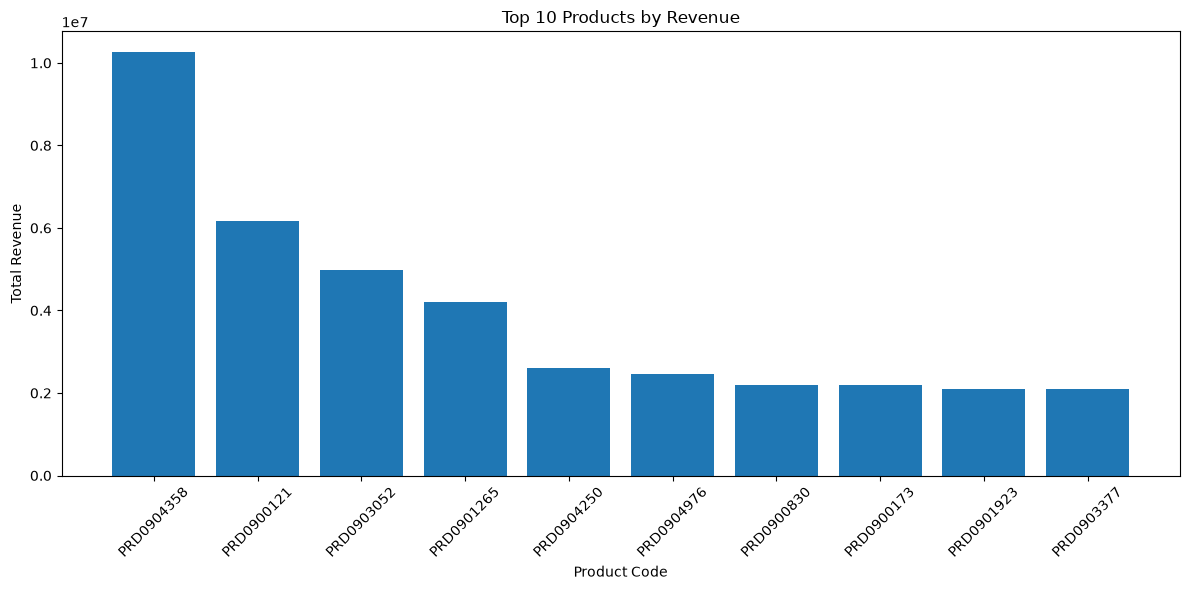

In [6]:
import matplotlib.pyplot as plt

top_revenue = product_df.nlargest(10, "total_revenue")

plt.figure(figsize=(12, 6))

plt.bar(
    top_revenue["PROD_CODE"],
    top_revenue["total_revenue"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Product Code")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

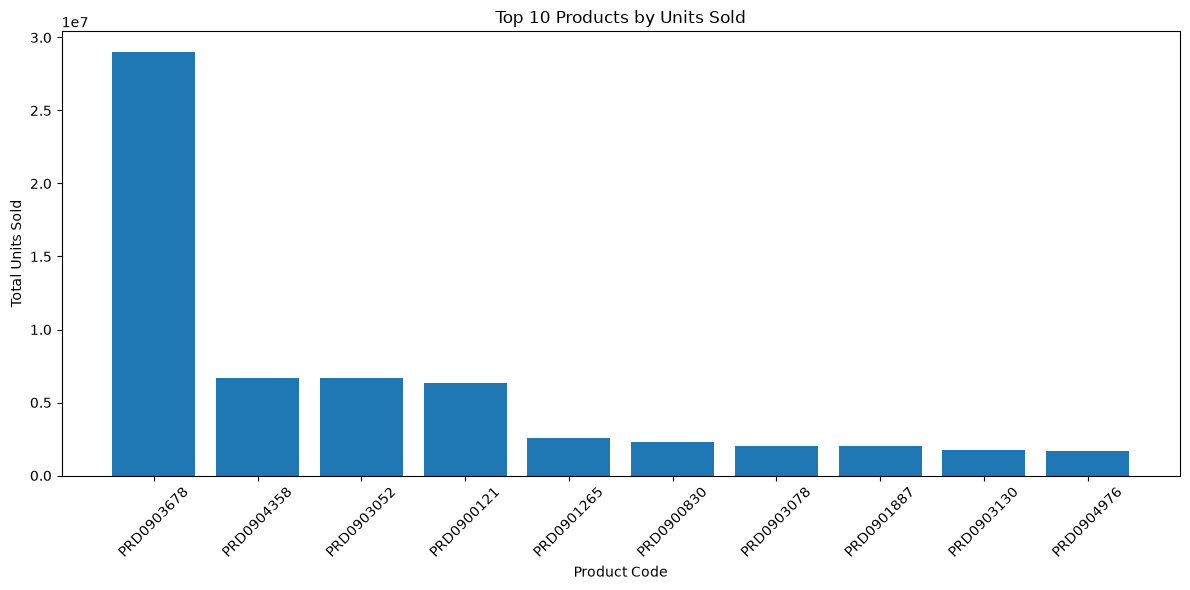

In [7]:
top_units = product_df.nlargest(10, "total_units")

plt.figure(figsize=(12, 6))

plt.bar(
    top_units["PROD_CODE"],
    top_units["total_units"]
)

plt.title("Top 10 Products by Units Sold")
plt.xlabel("Product Code")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

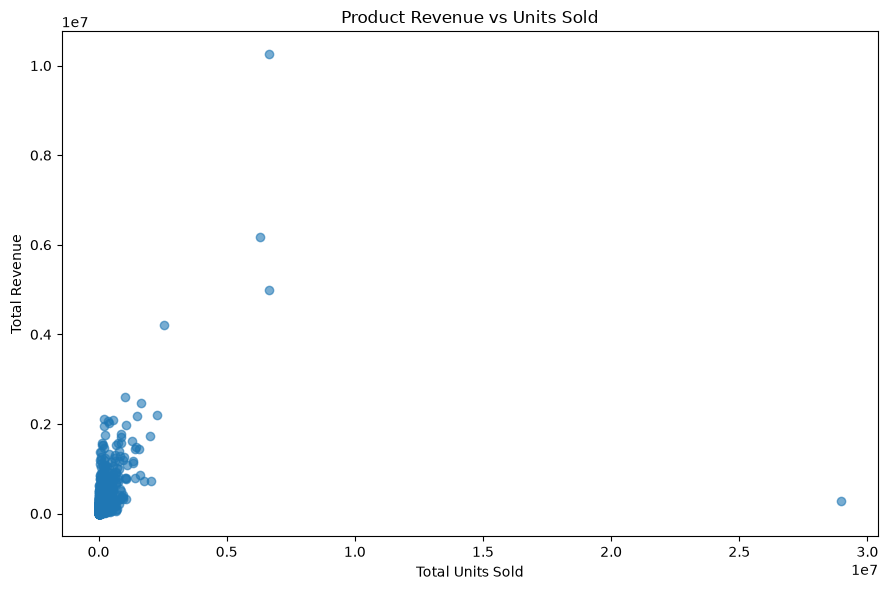

In [8]:
plt.figure(figsize=(9, 6))

plt.scatter(
    product_df["total_units"],
    product_df["total_revenue"],
    alpha=0.6
)

plt.title("Product Revenue vs Units Sold")
plt.xlabel("Total Units Sold")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

In [9]:
store_parts = []

for i, file in enumerate(files, start=1):

    query = """
    SELECT
        STORE_CODE,
        STORE_FORMAT,
        STORE_REGION,
        SUM(SPEND) AS total_revenue,
        SUM(QUANTITY) AS total_units,
        COUNT(*) AS transaction_rows
    FROM read_csv_auto(?)
    GROUP BY STORE_CODE, STORE_FORMAT, STORE_REGION
    """

    temp_df = con.execute(
        query, [file.as_posix()]
    ).df()

    store_parts.append(temp_df)

    if i % 10 == 0 or i == len(files):
        print(f"Processed {i}/{len(files)} files")

print("Store analysis completed!")

Processed 10/117 files
Processed 20/117 files
Processed 30/117 files
Processed 40/117 files
Processed 50/117 files
Processed 60/117 files
Processed 70/117 files
Processed 80/117 files
Processed 90/117 files
Processed 100/117 files
Processed 110/117 files
Processed 117/117 files
Store analysis completed!


In [10]:
store_df = (
    pd.concat(store_parts, ignore_index=True)
    .groupby(
        ["STORE_CODE", "STORE_FORMAT", "STORE_REGION"],
        as_index=False
    )
    .agg({
        "total_revenue": "sum",
        "total_units": "sum",
        "transaction_rows": "sum"
    })
    .sort_values("total_revenue", ascending=False)
)

print("Total stores:", len(store_df))
display(store_df.head(20))

Total stores: 761


,STORE_CODE,STORE_FORMAT,STORE_REGION,total_revenue,total_units,transaction_rows
187,STORE00696,XLS,E03,2405287.32,1760269.0,1162739
472,STORE01758,XLS,S01,2377295.80,1717702.0,1100963
198,STORE00729,XLS,W03,2262441.60,1645651.0,1077556
91,STORE00343,XLS,W02,2156792.76,1618556.0,1072314
386,STORE01423,XLS,E03,2136377.06,1621254.0,1063697
575,STORE02206,XLS,S02,2099111.01,1620282.0,1021266
609,STORE02339,XLS,E02,2086041.04,1564250.0,1028304
655,STORE02504,XLS,S03,2050161.96,1586189.0,1047283
433,STORE01604,XLS,W01,1988260.62,1572204.0,1010984
670,STORE02561,XLS,N01,1913164.77,1455127.0,930937


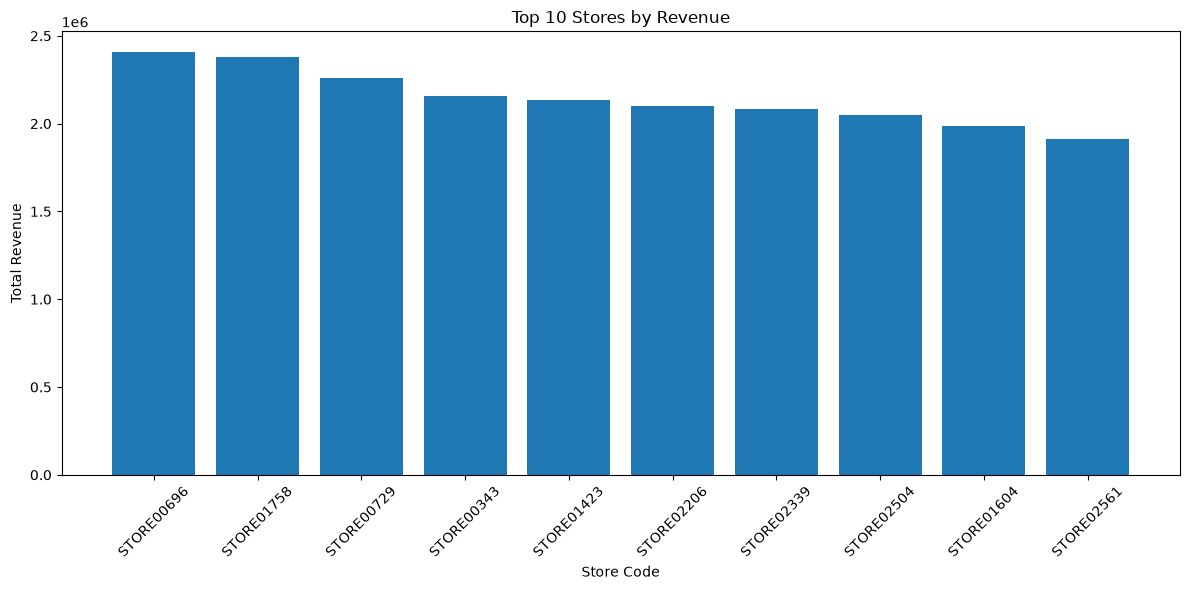

In [11]:
top_stores = store_df.nlargest(10, "total_revenue")

plt.figure(figsize=(12, 6))
plt.bar(top_stores["STORE_CODE"].astype(str),
        top_stores["total_revenue"])

plt.title("Top 10 Stores by Revenue")
plt.xlabel("Store Code")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

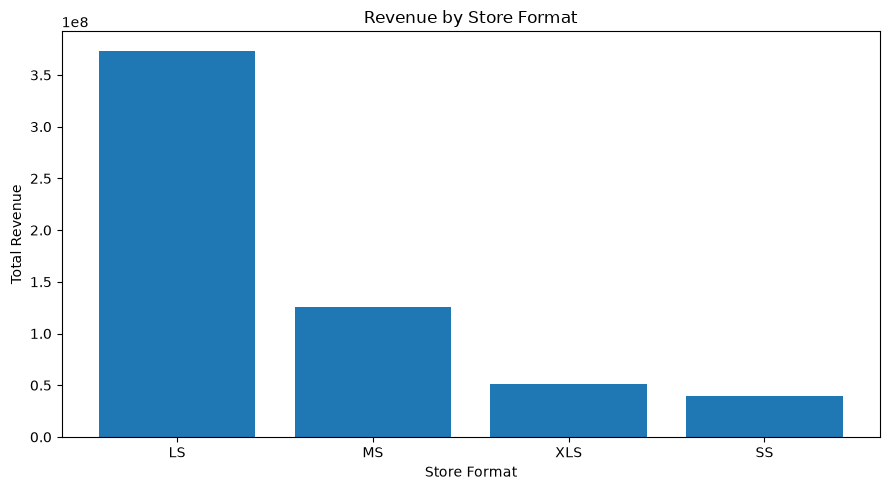

In [12]:
format_revenue = (
    store_df.groupby("STORE_FORMAT")["total_revenue"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
plt.bar(format_revenue.index.astype(str), format_revenue.values)

plt.title("Revenue by Store Format")
plt.xlabel("Store Format")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

In [13]:
segment_parts = []

for i, file in enumerate(files, start=1):

    query = """
    SELECT
        seg_1,
        seg_2,
        SUM(SPEND) AS total_revenue,
        SUM(QUANTITY) AS total_units,
        COUNT(*) AS transaction_rows,
        COUNT(DISTINCT CUST_CODE) AS unique_customers
    FROM read_csv_auto(?)
    GROUP BY seg_1, seg_2
    """

    temp_df = con.execute(
        query, [file.as_posix()]
    ).df()

    segment_parts.append(temp_df)

    if i % 10 == 0 or i == len(files):
        print(f"Processed {i}/{len(files)} files")

print("Segment analysis completed!")

Processed 10/117 files
Processed 20/117 files
Processed 30/117 files
Processed 40/117 files
Processed 50/117 files
Processed 60/117 files
Processed 70/117 files
Processed 80/117 files
Processed 90/117 files
Processed 100/117 files
Processed 110/117 files
Processed 117/117 files
Segment analysis completed!


In [14]:
segment_df = (
    pd.concat(segment_parts, ignore_index=True)
    .groupby(["seg_1", "seg_2"], dropna=False, as_index=False)
    .agg({
        "total_revenue": "sum",
        "total_units": "sum",
        "transaction_rows": "sum",
        "unique_customers": "sum"
    })
    .sort_values("total_revenue", ascending=False)
)

display(segment_df.head(20))

,seg_1,seg_2,total_revenue,total_units,transaction_rows,unique_customers
28,NaN,NaN,1.154495e+08,92058485.0,59534209,0
15,CT,BU,5.834518e+07,44573279.0,29771248,2511495
17,CT,DI,4.615612e+07,34994885.0,23498423,1507156
8,BG,BU,4.144226e+07,29285645.0,19581049,1783839
1,AZ,BU,3.188991e+07,27427068.0,17834774,1503002
3,AZ,DI,2.933542e+07,24933937.0,16508063,1082161
14,CT,AT,2.813593e+07,21534017.0,14884149,1329352
16,CT,CZ,2.726629e+07,22049343.0,14650763,1269797
20,CT,NaN,2.610848e+07,19915086.0,13488076,1048532
10,BG,DI,2.304337e+07,16227599.0,10783782,736756


In [16]:
print("Revenue dtype:", segment_revenue.dtype)
print("Index dtype:", segment_revenue.index.dtype)

display(segment_revenue.head(10))

Revenue dtype: float64
Index dtype: str


seg_1
CT     2.136691e+08
BG     1.379501e+08
AZ     1.218741e+08
NaN    1.154495e+08
DY     7.844318e+05
Name: total_revenue, dtype: float64

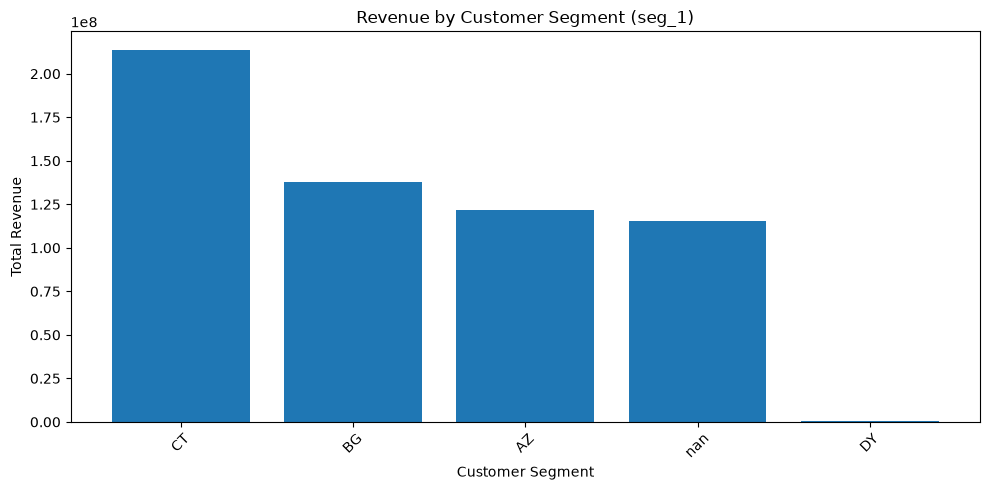

In [17]:
segment_revenue = pd.to_numeric(
    segment_revenue, errors="coerce"
).fillna(0)

labels = segment_revenue.index.astype(str)

plt.figure(figsize=(10, 5))

plt.bar(
    range(len(segment_revenue)),
    segment_revenue.values
)

plt.xticks(
    range(len(labels)),
    labels,
    rotation=45
)

plt.title("Revenue by Customer Segment (seg_1)")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")

plt.tight_layout()
plt.show()

In [18]:
segment_share = (
    segment_revenue / segment_revenue.sum()
) * 100

display(segment_share.round(2).to_frame("Revenue Share (%)"))

,Revenue Share (%)
seg_1,
CT,36.23
BG,23.39
AZ,20.67
NaN,19.58
DY,0.13


In [19]:
basket_parts = []

for i, file in enumerate(files, start=1):

    query = """
    SELECT
        BASKET_ID,
        BASKET_SIZE,
        BASKET_PRICE_SENSITIVITY,
        BASKET_TYPE,
        BASKET_DOMINANT_MISSION,
        SUM(SPEND) AS basket_revenue,
        SUM(QUANTITY) AS basket_units
    FROM read_csv_auto(?)
    GROUP BY
        BASKET_ID,
        BASKET_SIZE,
        BASKET_PRICE_SENSITIVITY,
        BASKET_TYPE,
        BASKET_DOMINANT_MISSION
    """

    temp_df = con.execute(
        query, [file.as_posix()]
    ).df()

    basket_parts.append(temp_df)

    if i % 10 == 0 or i == len(files):
        print(f"Processed {i}/{len(files)} files")

print("Basket analysis completed!")

Processed 10/117 files
Processed 20/117 files
Processed 30/117 files
Processed 40/117 files
Processed 50/117 files
Processed 60/117 files
Processed 70/117 files
Processed 80/117 files
Processed 90/117 files
Processed 100/117 files
Processed 110/117 files
Processed 117/117 files
Basket analysis completed!


In [20]:
basket_df = pd.concat(basket_parts, ignore_index=True)

print("Total basket records:", len(basket_df))

display(basket_df.head(10))

Total basket records: 47098503


,BASKET_ID,BASKET_SIZE,BASKET_PRICE_SENSITIVITY,BASKET_TYPE,BASKET_DOMINANT_MISSION,basket_revenue,basket_units
0,994100100253028,L,MM,Top Up,Mixed,14.13,10.0
1,994100100299966,L,UM,Top Up,Fresh,9.93,11.0
2,994100100237197,L,MM,Full Shop,Mixed,49.96,35.0
3,994100100715506,L,MM,Full Shop,Fresh,36.73,32.0
4,994100100749139,L,UM,Full Shop,Mixed,35.05,21.0
5,994100100100943,L,UM,Top Up,Fresh,32.01,18.0
6,994100100522743,L,LA,Full Shop,Fresh,47.78,41.0
7,994100100497892,L,MM,Top Up,Fresh,31.18,23.0
8,994100100572935,S,MM,Small Shop,Mixed,2.51,2.0
9,994100100259187,L,MM,Full Shop,Fresh,75.97,49.0


In [24]:
basket_kpis = pd.DataFrame({
    "Metric": [
        "Average Basket Value",
        "Average Basket Size",
        "Average Units per Basket",
        "Total Basket Revenue",
        "Total Basket Units"
    ],
    "Value": [
        basket_df["basket_revenue"].mean(),
        basket_df["BASKET_SIZE"].mean(),
        basket_df["basket_units"].mean(),
        basket_df["basket_revenue"].sum(),
        basket_df["basket_units"].sum()
    ]
})

display(basket_kpis)

,Metric,Value
0,Average Basket Value,1.252114e+01
1,Average Basket Size,NaN
2,Average Units per Basket,9.839138e+00
3,Total Basket Revenue,5.897272e+08
4,Total Basket Units,4.634087e+08


In [25]:
basket_type = (
    basket_df.groupby("BASKET_TYPE", dropna=False)
    .agg(
        total_revenue=("basket_revenue", "sum"),
        total_units=("basket_units", "sum"),
        basket_records=("BASKET_ID", "count")
    )
    .sort_values("total_revenue", ascending=False)
)

display(basket_type)

,total_revenue,total_units,basket_records
BASKET_TYPE,,,
Top Up,2.634893e+08,211232762.0,15604516
Full Shop,2.126799e+08,165318522.0,5266190
Small Shop,1.106909e+08,85431448.0,25619568
XX,2.867031e+06,1425933.0,608229


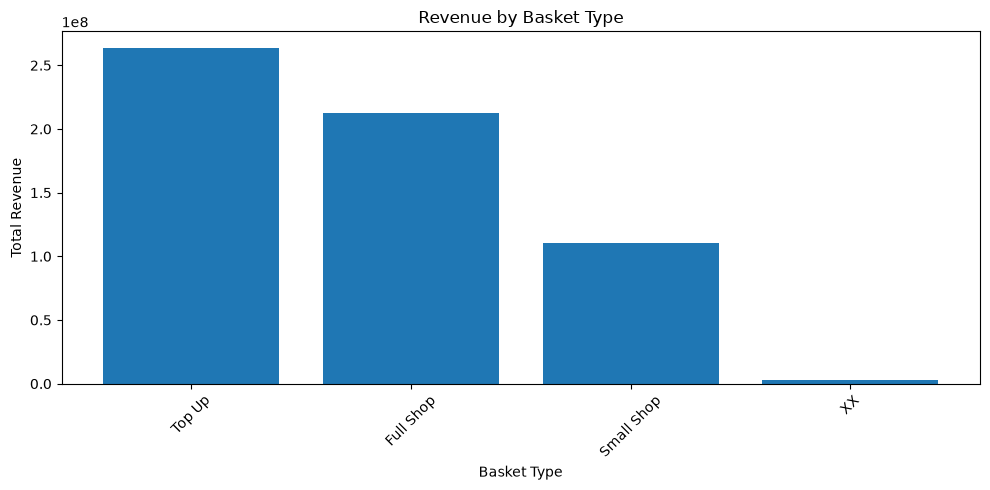

In [26]:
plt.figure(figsize=(10, 5))

plt.bar(
    basket_type.index.astype(str),
    basket_type["total_revenue"]
)

plt.title("Revenue by Basket Type")
plt.xlabel("Basket Type")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
mission_df = (
    basket_df.groupby("BASKET_DOMINANT_MISSION", dropna=False)
    .agg(
        total_revenue=("basket_revenue", "sum"),
        total_units=("basket_units", "sum"),
        basket_records=("BASKET_ID", "count")
    )
    .sort_values("total_revenue", ascending=False)
)

display(mission_df.head(15))

,total_revenue,total_units,basket_records
BASKET_DOMINANT_MISSION,,,
Fresh,2.805790e+08,222897793.0,23656819
Mixed,2.165183e+08,173752558.0,11457679
Grocery,7.818316e+07,58395146.0,8969602
Nonfood,1.157965e+07,6937235.0,2406174
XX,2.867031e+06,1425933.0,608229


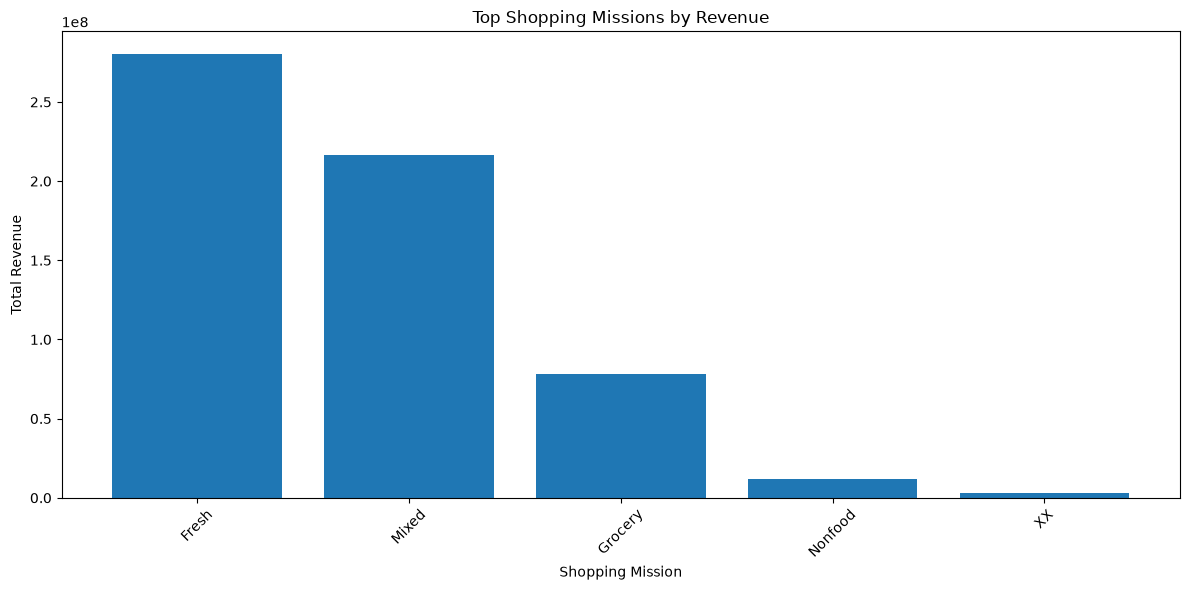

In [28]:
top_missions = mission_df.head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    top_missions.index.astype(str),
    top_missions["total_revenue"]
)

plt.title("Top Shopping Missions by Revenue")
plt.xlabel("Shopping Mission")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
monthly_parts = []

for i, file in enumerate(files, start=1):

    query = """
    SELECT
        DATE_TRUNC(
            'month',
            STRPTIME(CAST(SHOP_DATE AS VARCHAR), '%Y%m%d')
        ) AS sales_month,
        SUM(SPEND) AS total_revenue,
        SUM(QUANTITY) AS total_units,
        COUNT(*) AS transaction_rows
    FROM read_csv_auto(?)
    GROUP BY sales_month
    """

    temp_df = con.execute(
        query, [file.as_posix()]
    ).df()

    monthly_parts.append(temp_df)

    if i % 10 == 0 or i == len(files):
        print(f"Processed {i}/{len(files)} files")

print("Monthly aggregation completed!")

Processed 10/117 files
Processed 20/117 files
Processed 30/117 files
Processed 40/117 files
Processed 50/117 files
Processed 60/117 files
Processed 70/117 files
Processed 80/117 files
Processed 90/117 files
Processed 100/117 files
Processed 110/117 files
Processed 117/117 files
Monthly aggregation completed!


In [30]:
monthly_df = (
    pd.concat(monthly_parts, ignore_index=True)
    .groupby("sales_month", as_index=False)
    .agg({
        "total_revenue": "sum",
        "total_units": "sum",
        "transaction_rows": "sum"
    })
    .sort_values("sales_month")
)

display(monthly_df.head(15))
print("Total months:", len(monthly_df))

,sales_month,total_revenue,total_units,transaction_rows
0,2006-04-01,1.456060e+07,11112083.0,7657791
1,2006-05-01,2.188907e+07,16649274.0,11484182
2,2006-06-01,2.188354e+07,16454762.0,11337148
3,2006-07-01,2.265216e+07,17046186.0,11699689
4,2006-08-01,2.150047e+07,16760675.0,11475829
5,2006-09-01,2.127104e+07,16811950.0,11369269
6,2006-10-01,2.080979e+07,16616488.0,11388498
7,2006-11-01,2.128855e+07,16567312.0,11267435
8,2006-12-01,2.468093e+07,17425145.0,11519724
9,2007-01-01,2.083597e+07,16790074.0,11541170


Total months: 28


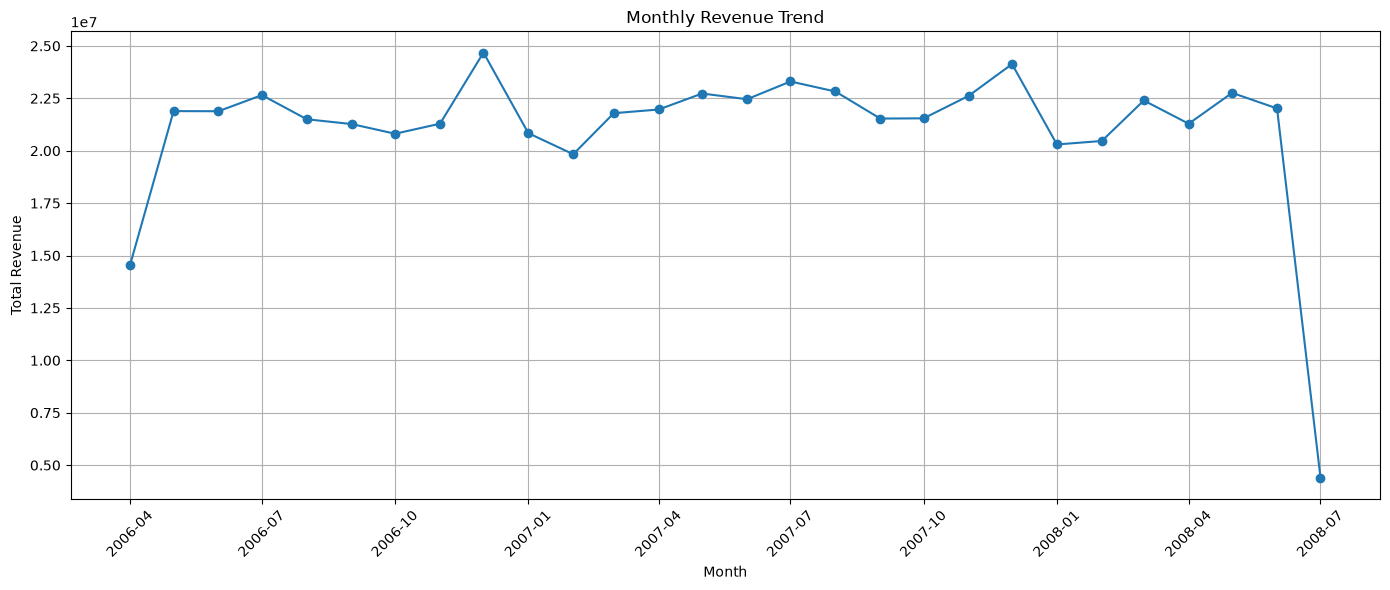

In [31]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_df["sales_month"],
    monthly_df["total_revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

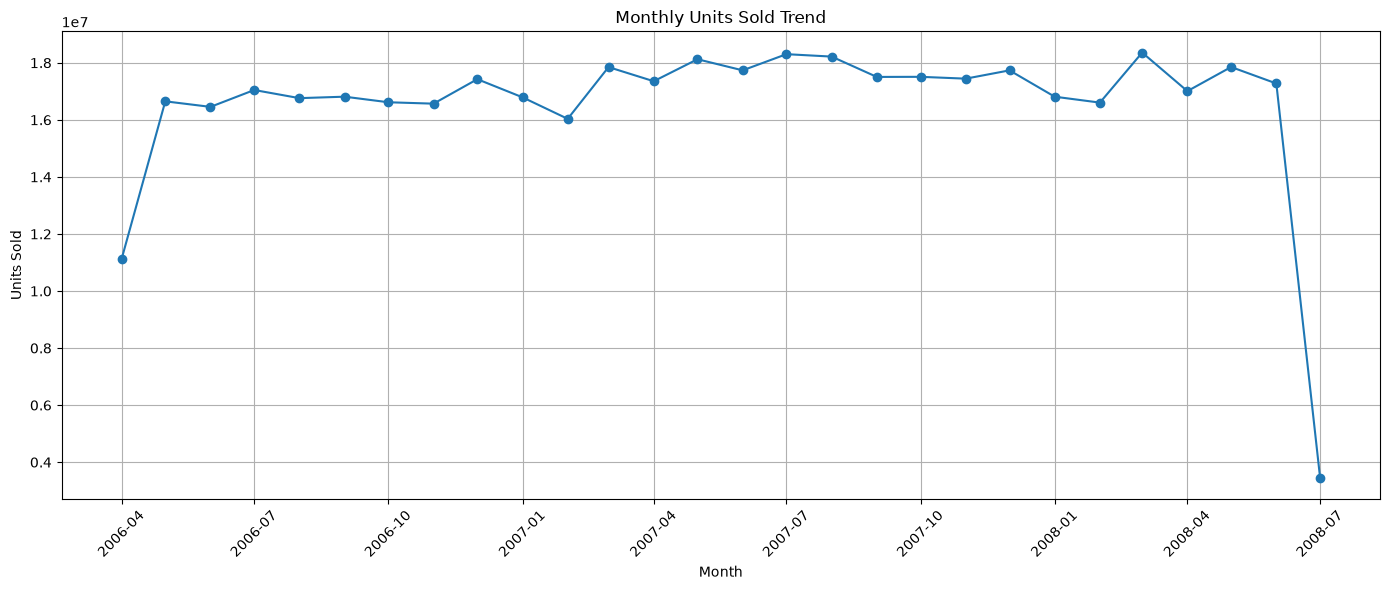

In [32]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_df["sales_month"],
    monthly_df["total_units"],
    marker="o"
)

plt.title("Monthly Units Sold Trend")
plt.xlabel("Month")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [33]:
quarterly_df = (
    monthly_df.assign(
        quarter=monthly_df["sales_month"].dt.to_period("Q")
    )
    .groupby("quarter", as_index=False)
    .agg({
        "total_revenue": "sum",
        "total_units": "sum",
        "transaction_rows": "sum"
    })
)

quarterly_df["quarter"] = quarterly_df["quarter"].astype(str)

display(quarterly_df)

,quarter,total_revenue,total_units,transaction_rows
0,2006Q2,5.833320e+07,44216119.0,30479121
1,2006Q3,6.542368e+07,50618811.0,34544787
2,2006Q4,6.677927e+07,50608945.0,34175657
3,2007Q1,6.245799e+07,50674665.0,34138081
4,2007Q2,6.715041e+07,53212819.0,35083230
5,2007Q3,6.766084e+07,54023940.0,35256682
6,2007Q4,6.829259e+07,52686578.0,33908084
7,2008Q1,6.315826e+07,51773389.0,33149242
8,2008Q2,6.606408e+07,52133543.0,34500596
9,2008Q3,4.406842e+06,3459856.0,2296593


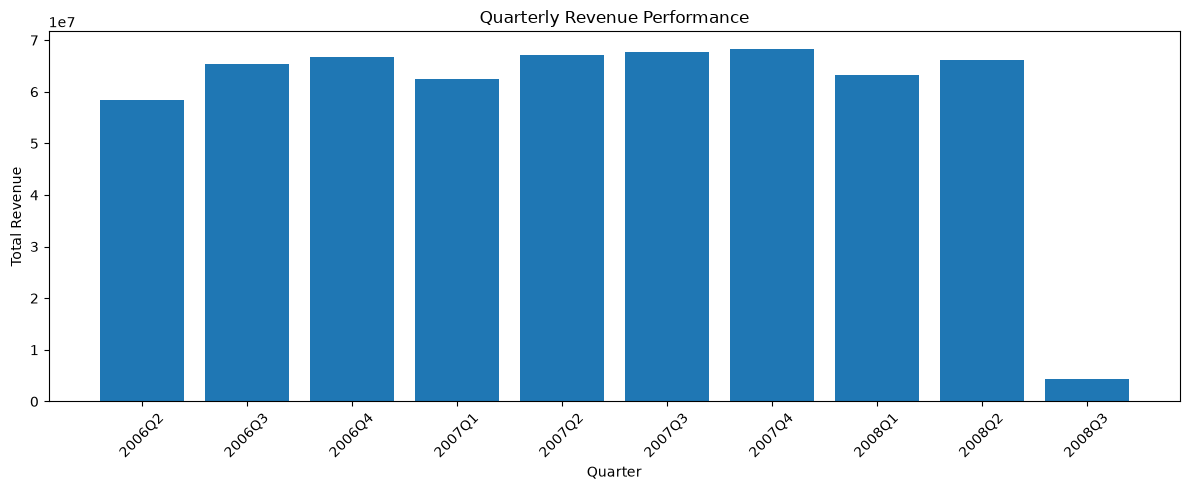

In [34]:
plt.figure(figsize=(12, 5))

plt.bar(
    quarterly_df["quarter"],
    quarterly_df["total_revenue"]
)

plt.title("Quarterly Revenue Performance")
plt.xlabel("Quarter")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [35]:
yearly_df = (
    monthly_df.assign(
        year=monthly_df["sales_month"].dt.year
    )
    .groupby("year", as_index=False)
    .agg({
        "total_revenue": "sum",
        "total_units": "sum",
        "transaction_rows": "sum"
    })
)

yearly_df["revenue_growth_pct"] = (
    yearly_df["total_revenue"].pct_change() * 100
)

display(yearly_df.round(2))

,year,total_revenue,total_units,transaction_rows,revenue_growth_pct
0,2006,1.905362e+08,145443875.0,99199565,NaN
1,2007,2.655618e+08,210598002.0,138386077,39.38
2,2008,1.336292e+08,107366788.0,69946431,-49.68


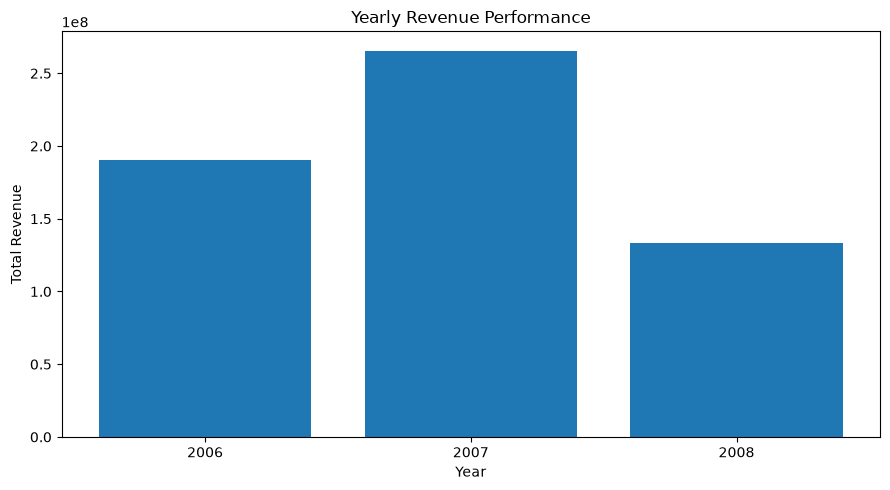

In [36]:
plt.figure(figsize=(9, 5))

plt.bar(
    yearly_df["year"].astype(str),
    yearly_df["total_revenue"]
)

plt.title("Yearly Revenue Performance")
plt.xlabel("Year")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

In [37]:
duplicate_parts = []

for i, file in enumerate(files, start=1):

    query = """
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT HASH(
            SHOP_WEEK, SHOP_DATE, SHOP_WEEKDAY,
            SHOP_HOUR, QUANTITY, SPEND,
            PROD_CODE, PROD_CODE_10, PROD_CODE_20,
            PROD_CODE_30, PROD_CODE_40, CUST_CODE,
            seg_1, seg_2, BASKET_ID, BASKET_SIZE,
            BASKET_PRICE_SENSITIVITY, BASKET_TYPE,
            BASKET_DOMINANT_MISSION, STORE_CODE,
            STORE_FORMAT, STORE_REGION
        )) AS unique_row_hashes
    FROM read_csv_auto(?)
    """

    result = con.execute(query, [file.as_posix()]).df()
    duplicate_parts.append(result)

    if i % 10 == 0 or i == len(files):
        print(f"Checked {i}/{len(files)} files")

print("Duplicate screening completed!")

Checked 10/117 files
Checked 20/117 files
Checked 30/117 files
Checked 40/117 files
Checked 50/117 files
Checked 60/117 files
Checked 70/117 files
Checked 80/117 files
Checked 90/117 files
Checked 100/117 files
Checked 110/117 files
Checked 117/117 files
Duplicate screening completed!


In [38]:
total_rows = sum(x["total_rows"].iloc[0] for x in duplicate_parts)

unique_hashes = sum(
    x["unique_row_hashes"].iloc[0]
    for x in duplicate_parts
)

print("Total rows:", total_rows)
print("Unique row hashes:", unique_hashes)
print("Potential duplicate rows:", total_rows - unique_hashes)

Total rows: 307532073
Unique row hashes: 307531968
Potential duplicate rows: 105


In [39]:
correlation = product_df[
    ["total_revenue", "total_units", "transaction_rows"]
].corr()

display(correlation.round(3))

,total_revenue,total_units,transaction_rows
total_revenue,1.000,0.384,0.747
total_units,0.384,1.000,0.749
transaction_rows,0.747,0.749,1.000


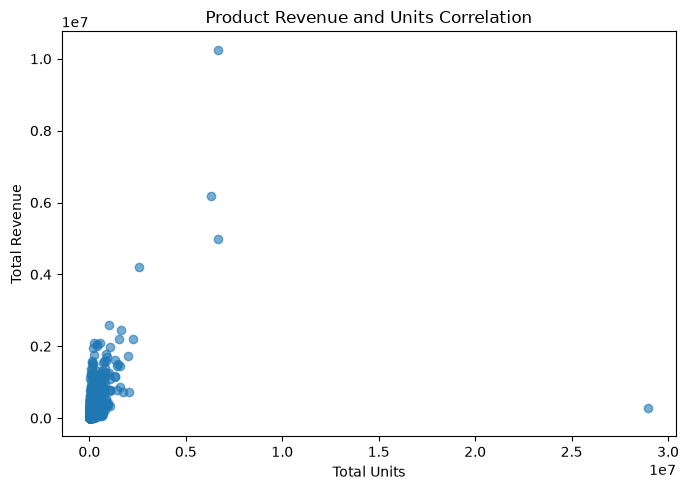

In [40]:
plt.figure(figsize=(7, 5))

plt.scatter(
    product_df["total_units"],
    product_df["total_revenue"],
    alpha=0.6
)

plt.title("Product Revenue and Units Correlation")
plt.xlabel("Total Units")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

In [41]:
OUTPUT = ROOT / "processed_data"
OUTPUT.mkdir(exist_ok=True)

product_df.to_csv(OUTPUT / "product_analysis.csv", index=False)
store_df.to_csv(OUTPUT / "store_analysis.csv", index=False)
segment_df.to_csv(OUTPUT / "customer_segment_analysis.csv", index=False)
monthly_df.to_csv(OUTPUT / "monthly_sales.csv", index=False)
quarterly_df.to_csv(OUTPUT / "quarterly_sales.csv", index=False)
yearly_df.to_csv(OUTPUT / "yearly_sales.csv", index=False)

print("All aggregated datasets exported!")
print("Saved at:", OUTPUT)

All aggregated datasets exported!
Saved at: D:\DS Project\Major\processed_data


In [42]:
from pathlib import Path

OUTPUT = ROOT / "processed_data"

required_files = [
    "product_analysis.csv",
    "store_analysis.csv",
    "customer_segment_analysis.csv",
    "monthly_sales.csv",
    "quarterly_sales.csv",
    "yearly_sales.csv"
]

for filename in required_files:
    path = OUTPUT / filename
    print(
        filename,
        "FOUND" if path.exists() else "MISSING"
    )

product_analysis.csv FOUND
store_analysis.csv FOUND
customer_segment_analysis.csv FOUND
monthly_sales.csv FOUND
quarterly_sales.csv FOUND
yearly_sales.csv FOUND


In [43]:
import duckdb

DB_PATH = ROOT / "retail_analytics.duckdb"

sql_con = duckdb.connect(str(DB_PATH))

print("Database created:", DB_PATH)

Database created: D:\DS Project\Major\retail_analytics.duckdb


In [44]:
tables = {
    "products": "product_analysis.csv",
    "stores": "store_analysis.csv",
    "customer_segments": "customer_segment_analysis.csv",
    "monthly_sales": "monthly_sales.csv",
    "quarterly_sales": "quarterly_sales.csv",
    "yearly_sales": "yearly_sales.csv"
}

for table_name, filename in tables.items():

    file_path = (OUTPUT / filename).as_posix()

    sql_con.execute(
        f"""
        CREATE OR REPLACE TABLE {table_name} AS
        SELECT * FROM read_csv_auto(?)
        """,
        [file_path]
    )

    print(f"Imported: {table_name}")

Imported: products
Imported: stores
Imported: customer_segments
Imported: monthly_sales
Imported: quarterly_sales
Imported: yearly_sales


In [45]:
sql_con.execute("SHOW TABLES").df()

,name
0,customer_segments
1,monthly_sales
2,products
3,quarterly_sales
4,stores
5,yearly_sales


In [46]:
result = sql_con.execute("""
    SELECT
        PROD_CODE,
        total_revenue,
        total_units,
        transaction_rows
    FROM products
    ORDER BY total_revenue DESC
    LIMIT 10
""").df()

display(result)

,PROD_CODE,total_revenue,total_units,transaction_rows
0,PRD0904358,1.025276e+07,6657638.0,4660102
1,PRD0900121,6.178918e+06,6305018.0,4171359
2,PRD0903052,4.988165e+06,6652710.0,6652710
3,PRD0901265,4.216820e+06,2563018.0,2563018
4,PRD0904250,2.593965e+06,1041753.0,908367
5,PRD0904976,2.456809e+06,1648865.0,1509630
6,PRD0900830,2.202092e+06,2270198.0,2040597
7,PRD0900173,2.188205e+06,1513958.0,1513958
8,PRD0901923,2.100017e+06,226539.0,105974
9,PRD0903377,2.095954e+06,555956.0,254099


In [48]:
query = """
SELECT
    PROD_CODE,
    total_revenue,
    total_units
FROM products
ORDER BY total_revenue DESC
LIMIT 10;
"""

result = sql_con.execute(query).df()

display(result)

,PROD_CODE,total_revenue,total_units
0,PRD0904358,1.025276e+07,6657638.0
1,PRD0900121,6.178918e+06,6305018.0
2,PRD0903052,4.988165e+06,6652710.0
3,PRD0901265,4.216820e+06,2563018.0
4,PRD0904250,2.593965e+06,1041753.0
5,PRD0904976,2.456809e+06,1648865.0
6,PRD0900830,2.202092e+06,2270198.0
7,PRD0900173,2.188205e+06,1513958.0
8,PRD0901923,2.100017e+06,226539.0
9,PRD0903377,2.095954e+06,555956.0


In [49]:
query = """
SELECT
    PROD_CODE,
    total_revenue,
    total_units,
    transaction_rows
FROM products
WHERE total_revenue > 1000000
ORDER BY total_revenue DESC;
"""

result = sql_con.execute(query).df()

display(result)

,PROD_CODE,total_revenue,total_units,transaction_rows
0,PRD0904358,1.025276e+07,6657638.0,4660102
1,PRD0900121,6.178918e+06,6305018.0,4171359
2,PRD0903052,4.988165e+06,6652710.0,6652710
3,PRD0901265,4.216820e+06,2563018.0,2563018
4,PRD0904250,2.593965e+06,1041753.0,908367
5,PRD0904976,2.456809e+06,1648865.0,1509630
6,PRD0900830,2.202092e+06,2270198.0,2040597
7,PRD0900173,2.188205e+06,1513958.0,1513958
8,PRD0901923,2.100017e+06,226539.0,105974
9,PRD0903377,2.095954e+06,555956.0,254099


In [50]:
query = """
SELECT
    ROUND(SUM(total_revenue), 2) AS total_revenue,
    SUM(total_units) AS total_units,
    SUM(transaction_rows) AS total_transaction_rows,
    COUNT(*) AS unique_products,
    ROUND(AVG(total_revenue), 2) AS avg_product_revenue
FROM products;
"""

result = sql_con.execute(query).df()

display(result)

,total_revenue,total_units,total_transaction_rows,unique_products,avg_product_revenue
0,589727167.5,463408665.0,307532073.0,4997,118016.24


In [51]:
query = """
SELECT
    PROD_CODE_10,
    ROUND(SUM(total_revenue), 2) AS category_revenue,
    SUM(total_units) AS units_sold
FROM products
GROUP BY PROD_CODE_10
ORDER BY category_revenue DESC;
"""

result = sql_con.execute(query).df()

display(result)

,PROD_CODE_10,category_revenue,units_sold
0,CL00063,23913711.97,20264260.0
1,CL00067,14976858.14,7799245.0
2,CL00058,14495196.76,2962821.0
3,CL00201,12924803.07,6191730.0
4,CL00229,12842517.55,1873617.0
...,...,...,...
245,CL00183,8984.70,9983.0
246,CL00184,7843.58,20641.0
247,CL00181,3357.48,15988.0
248,CL00241,524.01,52401.0


In [52]:
query = """
SELECT
    m.sales_month,
    m.total_revenue AS monthly_revenue,
    y.total_revenue AS yearly_revenue,
    y.year
FROM monthly_sales m
INNER JOIN yearly_sales y
    ON EXTRACT(YEAR FROM m.sales_month) = y.year
ORDER BY m.sales_month;
"""

result = sql_con.execute(query).df()

display(result.head(20))

,sales_month,monthly_revenue,yearly_revenue,year
0,2006-04-01,1.456060e+07,1.905362e+08,2006
1,2006-05-01,2.188907e+07,1.905362e+08,2006
2,2006-06-01,2.188354e+07,1.905362e+08,2006
3,2006-07-01,2.265216e+07,1.905362e+08,2006
4,2006-08-01,2.150047e+07,1.905362e+08,2006
5,2006-09-01,2.127104e+07,1.905362e+08,2006
6,2006-10-01,2.080979e+07,1.905362e+08,2006
7,2006-11-01,2.128855e+07,1.905362e+08,2006
8,2006-12-01,2.468093e+07,1.905362e+08,2006
9,2007-01-01,2.083597e+07,2.655618e+08,2007


In [53]:
query = """
SELECT
    m.sales_month,
    m.total_revenue AS monthly_revenue,
    y.total_revenue AS yearly_revenue
FROM monthly_sales m
LEFT JOIN yearly_sales y
    ON EXTRACT(YEAR FROM m.sales_month) = y.year
ORDER BY m.sales_month;
"""

result = sql_con.execute(query).df()

display(result.head(20))

,sales_month,monthly_revenue,yearly_revenue
0,2006-04-01,1.456060e+07,1.905362e+08
1,2006-05-01,2.188907e+07,1.905362e+08
2,2006-06-01,2.188354e+07,1.905362e+08
3,2006-07-01,2.265216e+07,1.905362e+08
4,2006-08-01,2.150047e+07,1.905362e+08
5,2006-09-01,2.127104e+07,1.905362e+08
6,2006-10-01,2.080979e+07,1.905362e+08
7,2006-11-01,2.128855e+07,1.905362e+08
8,2006-12-01,2.468093e+07,1.905362e+08
9,2007-01-01,2.083597e+07,2.655618e+08


In [54]:
query = """
SELECT
    m.sales_month,
    ROUND(m.total_revenue, 2) AS monthly_revenue,
    ROUND(
        m.total_revenue * 100.0 /
        NULLIF(y.total_revenue, 0),
        2
    ) AS yearly_revenue_contribution_pct
FROM monthly_sales m
JOIN yearly_sales y
    ON EXTRACT(YEAR FROM m.sales_month) = y.year
ORDER BY m.sales_month;
"""

result = sql_con.execute(query).df()

display(result)

,sales_month,monthly_revenue,yearly_revenue_contribution_pct
0,2006-04-01,14560595.32,7.64
1,2006-05-01,21889065.99,11.49
2,2006-06-01,21883540.96,11.49
3,2006-07-01,22652162.16,11.89
4,2006-08-01,21500471.36,11.28
5,2006-09-01,21271044.97,11.16
6,2006-10-01,20809793.17,10.92
7,2006-11-01,21288552.33,11.17
8,2006-12-01,24680929.00,12.95
9,2007-01-01,20835965.04,7.85


In [55]:
query = """
WITH product_revenue AS (
    SELECT
        PROD_CODE,
        total_revenue,
        total_units
    FROM products
),
ranked_products AS (
    SELECT
        *,
        PERCENT_RANK() OVER (
            ORDER BY total_revenue DESC
        ) AS revenue_percentile
    FROM product_revenue
)

SELECT *
FROM ranked_products
WHERE revenue_percentile <= 0.10
ORDER BY total_revenue DESC;
"""

result = sql_con.execute(query).df()

display(result)

,PROD_CODE,total_revenue,total_units,revenue_percentile
0,PRD0904358,1.025276e+07,6657638.0,0.000000
1,PRD0900121,6.178918e+06,6305018.0,0.000200
2,PRD0903052,4.988165e+06,6652710.0,0.000400
3,PRD0901265,4.216820e+06,2563018.0,0.000600
4,PRD0904250,2.593965e+06,1041753.0,0.000801
...,...,...,...,...
495,PRD0902294,2.396766e+05,35006.0,0.099079
496,PRD0902638,2.393838e+05,107347.0,0.099279
497,PRD0902195,2.391122e+05,60998.0,0.099480
498,PRD0902910,2.390444e+05,61451.0,0.099680


In [56]:
query = """
SELECT
    PROD_CODE,
    total_revenue,
    total_units
FROM products
WHERE total_revenue > (
    SELECT AVG(total_revenue)
    FROM products
)
ORDER BY total_revenue DESC;
"""

result = sql_con.execute(query).df()

display(result)

,PROD_CODE,total_revenue,total_units
0,PRD0904358,1.025276e+07,6657638.0
1,PRD0900121,6.178918e+06,6305018.0
2,PRD0903052,4.988165e+06,6652710.0
3,PRD0901265,4.216820e+06,2563018.0
4,PRD0904250,2.593965e+06,1041753.0
...,...,...,...
1224,PRD0904252,1.183092e+05,200524.0
1225,PRD0902525,1.183014e+05,56334.0
1226,PRD0904047,1.183013e+05,58565.0
1227,PRD0901577,1.182476e+05,179163.0


In [57]:
query = """
WITH store_ranking AS (
    SELECT
        STORE_CODE,
        STORE_FORMAT,
        STORE_REGION,
        total_revenue,
        RANK() OVER (
            ORDER BY total_revenue DESC
        ) AS revenue_rank
    FROM stores
)

SELECT *
FROM store_ranking
WHERE revenue_rank <= 10
ORDER BY revenue_rank;
"""

result = sql_con.execute(query).df()

display(result)

,STORE_CODE,STORE_FORMAT,STORE_REGION,total_revenue,revenue_rank
0,STORE00696,XLS,E03,2405287.32,1
1,STORE01758,XLS,S01,2377295.80,2
2,STORE00729,XLS,W03,2262441.60,3
3,STORE00343,XLS,W02,2156792.76,4
4,STORE01423,XLS,E03,2136377.06,5
5,STORE02206,XLS,S02,2099111.01,6
6,STORE02339,XLS,E02,2086041.04,7
7,STORE02504,XLS,S03,2050161.96,8
8,STORE01604,XLS,W01,1988260.62,9
9,STORE02561,XLS,N01,1913164.77,10


In [58]:
query = """
WITH monthly_comparison AS (
    SELECT
        sales_month,
        total_revenue,
        LAG(total_revenue) OVER (
            ORDER BY sales_month
        ) AS previous_month_revenue
    FROM monthly_sales
)

SELECT
    sales_month,
    ROUND(total_revenue, 2) AS current_revenue,
    ROUND(previous_month_revenue, 2) AS previous_revenue,
    ROUND(
        (total_revenue - previous_month_revenue)
        * 100.0 / NULLIF(previous_month_revenue, 0),
        2
    ) AS growth_percentage
FROM monthly_comparison
ORDER BY sales_month;
"""

result = sql_con.execute(query).df()

display(result)

,sales_month,current_revenue,previous_revenue,growth_percentage
0,2006-04-01,14560595.32,NaN,NaN
1,2006-05-01,21889065.99,14560595.32,50.33
2,2006-06-01,21883540.96,21889065.99,-0.03
3,2006-07-01,22652162.16,21883540.96,3.51
4,2006-08-01,21500471.36,22652162.16,-5.08
5,2006-09-01,21271044.97,21500471.36,-1.07
6,2006-10-01,20809793.17,21271044.97,-2.17
7,2006-11-01,21288552.33,20809793.17,2.30
8,2006-12-01,24680929.00,21288552.33,15.94
9,2007-01-01,20835965.04,24680929.00,-15.58


In [59]:
sql_con.execute("""
CREATE OR REPLACE VIEW vw_product_sales AS
SELECT
    PROD_CODE,
    PROD_CODE_10,
    PROD_CODE_20,
    PROD_CODE_30,
    PROD_CODE_40,
    total_revenue,
    total_units,
    transaction_rows,
    ROUND(
        total_revenue / NULLIF(total_units, 0),
        2
    ) AS revenue_per_unit
FROM products;
""")

print("Product sales view created!")

Product sales view created!


In [60]:
sql_con.execute("""
CREATE OR REPLACE VIEW vw_store_sales AS
SELECT
    STORE_CODE,
    STORE_FORMAT,
    STORE_REGION,
    total_revenue,
    total_units,
    transaction_rows
FROM stores;
""")

print("Store sales view created!")

Store sales view created!


In [61]:
sql_con.execute("""
CREATE OR REPLACE VIEW vw_monthly_sales AS
SELECT
    sales_month,
    total_revenue,
    total_units,
    transaction_rows,
    LAG(total_revenue) OVER (
        ORDER BY sales_month
    ) AS previous_month_revenue
FROM monthly_sales;
""")

print("Monthly sales view created!")

Monthly sales view created!


In [62]:
sql_con.execute("""
CREATE OR REPLACE VIEW vw_customer_segments AS
SELECT
    seg_1,
    seg_2,
    total_revenue,
    total_units,
    transaction_rows,
    ROUND(
        total_revenue * 100.0 /
        NULLIF(SUM(total_revenue) OVER (), 0),
        2
    ) AS revenue_contribution_pct
FROM customer_segments;
""")

print("Customer segment view created!")

Customer segment view created!


In [63]:
display(
    sql_con.execute("""
        SELECT
            table_name
        FROM information_schema.views
        WHERE table_schema = 'main'
        ORDER BY table_name
    """).df()
)

,table_name
0,duckdb_columns
1,duckdb_constraints
2,duckdb_databases
3,duckdb_indexes
4,duckdb_logs
5,duckdb_schemas
6,duckdb_tables
7,duckdb_types
8,duckdb_views
9,pragma_database_list


In [64]:
result = sql_con.execute("""
    SELECT *
    FROM vw_product_sales
    ORDER BY total_revenue DESC
    LIMIT 10
""").df()

display(result)

,PROD_CODE,PROD_CODE_10,PROD_CODE_20,PROD_CODE_30,PROD_CODE_40,total_revenue,total_units,transaction_rows,revenue_per_unit
0,PRD0904358,CL00063,DEP00019,G00007,D00002,1.025276e+07,6657638.0,4660102,1.54
1,PRD0900121,CL00063,DEP00019,G00007,D00002,6.178918e+06,6305018.0,4171359,0.98
2,PRD0903052,CL00031,DEP00008,G00004,D00002,4.988165e+06,6652710.0,6652710,0.75
3,PRD0901265,CL00030,DEP00008,G00004,D00002,4.216820e+06,2563018.0,2563018,1.65
4,PRD0904250,CL00045,DEP00011,G00004,D00002,2.593965e+06,1041753.0,908367,2.49
5,PRD0904976,CL00040,DEP00010,G00004,D00002,2.456809e+06,1648865.0,1509630,1.49
6,PRD0900830,CL00043,DEP00011,G00004,D00002,2.202092e+06,2270198.0,2040597,0.97
7,PRD0900173,CL00045,DEP00011,G00004,D00002,2.188205e+06,1513958.0,1513958,1.45
8,PRD0901923,CL00229,DEP00081,G00027,D00008,2.100017e+06,226539.0,105974,9.27
9,PRD0903377,CL00086,DEP00024,G00007,D00002,2.095954e+06,555956.0,254099,3.77


In [65]:
from pathlib import Path

POWERBI_DIR = ROOT / "powerbi_data"
POWERBI_DIR.mkdir(exist_ok=True)

views = [
    "vw_product_sales",
    "vw_store_sales",
    "vw_monthly_sales",
    "vw_customer_segments"
]

for view in views:

    df = sql_con.execute(
        f"SELECT * FROM {view}"
    ).df()

    df.to_csv(
        POWERBI_DIR / f"{view}.csv",
        index=False
    )

    print(f"Exported: {view}.csv | Rows: {len(df)}")

Exported: vw_product_sales.csv | Rows: 4997
Exported: vw_store_sales.csv | Rows: 761
Exported: vw_monthly_sales.csv | Rows: 28
Exported: vw_customer_segments.csv | Rows: 29


In [ ]:
con.execute("CHECKPOINT")
con.close()

NameError: name 'con' is not defined